# Paper figures

This notebook generates the paper figures from the six executed campaigns and the
Nav2 system-test results. Per-run coverage in Figure 2 uses cached node traces
(`bt_coverage_cache/*_reached.json`); in their absence it decodes the `rosbag2/`
directories directly (needs `rosbags`).

* **Figure 1** (`fig1_coverage.png`, paper Fig.~\ref{fig:cov}) \--- coverage per
  batch for a representative campaign (`nav_to_pose`, offices).
* **Figure 2** (`fig2_detail.png`, paper Fig.~\ref{fig:detail}) \--- three-panel
  coverage-over-time detail for the same campaign: per-batch unit spread,
  per-run coverage distribution, cumulative distinct nodes triggered.



In [1]:
from __future__ import annotations
import json, sqlite3
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl

DATA_ROOT = Path("/home/sam/Downloads/ICRA analysis")
OPT = DATA_ROOT / "optimization_tests"
SYSTEM_ROOT = DATA_ROOT / "nav2_system_tests"

sns_bool = False
try:
    import seaborn as sns
    sns_bool = True
except ImportError:
    pass

SINGLE_COLUMN = 3.4  # Single column
TWO_COLUMNS = 7      # Two columns

plt.style.use(str(DATA_ROOT / "ieee.txt"))

import matplotlib.font_manager as _fm
_fm.fontManager = _fm.FontManager()  # rebuild font list; finds freshly-installed Times New Roman

mpl.rcParams["figure.dpi"] = 110

def _camp_dir(suffix):
    return OPT / f"{suffix}.incomplete" / suffix

CAMPAIGNS = {
    "nav_to_pose_secorolab":       _camp_dir("qd-nav-to-pose-secorolab-2026-09-08-01140915"),
    "nav_to_pose_hexagon":         _camp_dir("qd-nav-to-pose-hexagon-2026-09-08-01141390"),
    "nav_through_poses_secorolab": _camp_dir("qd-nav-through-poses-secorolab-2026-09-08-01141901"),
    "nav_through_poses_hexagon":   _camp_dir("qd-nav-through-poses-hexagon-2026-09-08-01142436"),
    "follow_waypoints_secorolab":  _camp_dir("qd-follow-waypoints-secorolab-2026-09-08-01142971"),
    "follow_waypoints_hexagon":    _camp_dir("qd-follow-waypoints-hexagon-2026-09-08-01143461"),
}
for n, d in CAMPAIGNS.items():
    assert d.is_dir(), f"missing campaign dir: {d}"
print("campaigns:", ", ".join(CAMPAIGNS))


/home/sam/.local/lib/python3.12/site-packages/pandas/core/arrays/masked.py:61: UserWarning: Pandas requires version '1.3.6' or newer of 'bottleneck' (version '1.3.5' currently installed).
  from pandas.core import (


/home/sam/.local/lib/python3.12/site-packages/matplotlib/projections/__init__.py:63: UserWarning: Unable to import Axes3D. This may be due to multiple versions of Matplotlib being installed (e.g. as a system package and as a pip package). As a result, the 3D projection is not available.
  warnings.warn("Unable to import Axes3D. This may be due to multiple versions of "


campaigns: nav_to_pose_secorolab, nav_to_pose_hexagon, nav_through_poses_secorolab, nav_through_poses_hexagon, follow_waypoints_secorolab, follow_waypoints_hexagon


In [2]:
def load_campaign(name):
    root = CAMPAIGNS[name]
    conn = sqlite3.connect(root / "campaign.db")
    conn.row_factory = sqlite3.Row
    camp = dict(conn.execute("SELECT * FROM campaign").fetchone())
    units = pd.DataFrame([
        dict(r) for r in conn.execute(
            "SELECT b.idx AS batch, u.id AS unit_id, u.paramset_id, u.config_name, "
            "u.objective, u.params_json, u.measures_json, u.status, u.n_samples "
            "FROM unit u JOIN batch b ON u.batch_id = b.id ORDER BY b.idx, u.id")])
    conn.close()
    cfg = json.loads(camp["config_json"])
    return dict(name=name, root=root, db=camp, config=cfg, units=units)

campaigns = {n: load_campaign(n) for n in CAMPAIGNS}
for n, c in campaigns.items():
    print(f"{n}: {len(c['units'])} parameter sets, "
          f"{c['units']['objective'].notna().sum()} with objective")


nav_to_pose_secorolab: 120 parameter sets, 119 with objective
nav_to_pose_hexagon: 120 parameter sets, 118 with objective
nav_through_poses_secorolab: 120 parameter sets, 120 with objective
nav_through_poses_hexagon: 120 parameter sets, 118 with objective
follow_waypoints_secorolab: 120 parameter sets, 117 with objective
follow_waypoints_hexagon: 120 parameter sets, 85 with objective


In [3]:
# --- Nav2 system-test baseline: combined suite coverage over the 25-node behaviour universe ---
def parse_bt_xml(xml_path):
    """Flatten a BehaviorTree.CPP XML the way RoboVAST does."""
    from xml.etree import ElementTree
    root = ElementTree.parse(xml_path).getroot()
    trees = {bt.get("ID"): bt for bt in root.iter("BehaviorTree")}
    main_id = root.get("main_tree_to_execute")
    main = trees.get(main_id) if main_id else None
    if main is None:
        main = next(iter(trees.values()), None)
    name_of = lambda el: el.get("name") or el.tag
    names, parents, classes = [], {}, {}

    def walk(el, pid, active):
        nid = len(names)
        names.append(name_of(el)); parents[nid] = pid; classes[nid] = el.tag
        me = nid
        for ch in list(el):
            if ch.tag == "SubTree":
                ref = ch.get("ID"); sub = trees.get(ref)
                if sub is not None and ref not in active:
                    for sc in list(sub):
                        walk(sc, me, active | {ref})
                continue
            walk(ch, me, active)

    for ch in list(main):
        walk(ch, None, frozenset({main_id} if main_id else set()))
    return dict(names=names, parents=parents, classes=classes)

def _covered_from_csv(csv_path):
    import csv
    out = set()
    with open(csv_path) as f:
        for row in csv.DictReader(f):
            if row.get("status_name", "") not in ("INVALID", "IDLE", ""):
                out.add(row["behavior_name"])
    return out

def system_test_baseline():
    """Combined coverage of the whole nav2 system-test suite over the 25-node
    behaviour universe = the union of the two navigation trees' node sets. Nodes count
    as covered if the behaviour logs reached them inside a tree or, for the in-tree
    behaviours Spin and Wait, through direct behaviour-server calls."""
    to_pose_xml = SYSTEM_ROOT / "system" / "test-bt-navigator-2026-09-06-10075304" \
                  / "_config" / "files" / "navigate_to_pose_w_replanning_and_recovery.xml"
    thru_xml = SYSTEM_ROOT / "system" / "test-nav-through-poses-2026-09-06-10461058" \
               / "_config" / "files" / "navigate_through_poses_w_replanning_and_recovery.xml"
    decl_to_pose = set(parse_bt_xml(to_pose_xml)["names"])
    decl_thru = set(parse_bt_xml(thru_xml)["names"])
    UNIVERSE = decl_to_pose | decl_thru

    # behaviours exercised through the behaviour tree (per-run nav2_behaviors.csv)
    bt_covered = set()
    for csvp in SYSTEM_ROOT.rglob("nav2_behaviors.csv"):
        if not csvp.parent.name.isdigit():
            continue
        bt_covered |= _covered_from_csv(csvp)

    # behaviours exercised only by *direct* calls to the behaviour server
    # in-tree behaviours reached only through direct behaviour-server calls (decision B)
    DIRECT_MAP = {
        "test-spin-behavior-2026-09-06-15094116":             {"Spin"},
        "test-wait-behavior-2026-09-06-15015548":             {"Wait"},
        "test-error-codes-2026-09-06-14382214":               {"FollowPath", "ComputePathToPose",
                                                               "ComputePathThroughPoses"},
    }
    direct = set().union(*DIRECT_MAP.values())
    covered = (bt_covered | direct) & UNIVERSE

    # min coverage across per-run bags and the best-so-far, for cross-checks
    return len(covered), len(UNIVERSE), len(covered & decl_to_pose), len(covered & decl_thru)

N_COVERED, N_UNIVERSE, N_T22, N_T24 = system_test_baseline()
print(f"combined nav2 system-test suite: {N_COVERED}/{N_UNIVERSE} behaviours "
      f"= {N_COVERED / N_UNIVERSE:.1%}  |  per-tree: {N_T22}/22 = {N_T22 / 22:.1%}, "
      f"{N_T24}/24 = {N_T24 / 24:.1%}")


combined nav2 system-test suite: 12/25 behaviours = 48.0%  |  per-tree: 9/22 = 40.9%, 11/24 = 45.8%


In [4]:
# fig:cov dotted line = stock suite coverage on the to-pose tree, 9/22 = 40.9% (paper RQ1)
BASELINE = N_T22 / 22
print(f"fig:cov baseline (to-pose tree): {BASELINE:.3f} ({BASELINE:.1%}) = {N_T22}/22")


fig:cov baseline (to-pose tree): 0.409 (40.9%) = 9/22


saved: /home/sam/Downloads/ICRA analysis/fig1.png  (baseline=0.409, band min=0.318 which is 31.8%)


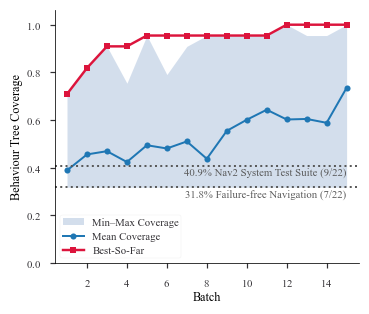

In [5]:
NAME = "nav_to_pose_secorolab"
TITLE = "Coverage over Batches Using nav_to_pose on the offices Map"

fig, ax = plt.subplots(figsize=(SINGLE_COLUMN, 2.9))
u = campaigns[NAME]["units"].dropna(subset=["objective"]).copy()
perf = u.groupby("batch")["objective"].agg(["mean", "min", "max"])
best = perf["max"].cummax()
x = perf.index + 1

ax.fill_between(x, perf["min"].values, perf["max"].values,
                color="lightsteelblue", alpha=0.55, lw=0,
                label="Min–Max Coverage")
ax.plot(x, perf["mean"].values, marker="o", ms=4, ls="-",
        color="tab:blue", lw=1.3, label="Mean Coverage")
ax.plot(x, best.values, marker="s", ms=4, ls="-", color="crimson", lw=1.6,
        label="Best-So-Far")
ax.axhline(BASELINE, ls=":", c="0.35", lw=1.3)
ax.text(x[-1], BASELINE - 0.008, f"{100*BASELINE:.1f}% Nav2 System Test Suite (9/22)", ha="right",
        va="top", fontsize=7, color="0.35")
ax.axhline(0.318, ls=":", c="0.35", lw=1.3)
ax.text(x[-1], 0.318 - 0.008, f"{100*0.318:.1f}% Failure-free Navigation (7/22)", ha="right",
        va="top", fontsize=7, color="0.35")

ax.set_ylim(0, 1.06)
ax.set_xlim(0.4, 15.6)
ax.set_xlabel("Batch", fontsize=8)
ax.set_ylabel("Behaviour Tree Coverage", fontsize=8)
ax.tick_params(labelsize=7)
ax.legend(fontsize=7, loc="lower left", frameon=True, ncol=1)
fig.tight_layout()
fout = DATA_ROOT / "fig1.png"
fig.savefig(fout, dpi=300, bbox_inches="tight")
print(f"saved: {fout}  (baseline={BASELINE:.3f}, band min={perf['min'].min():.3f} "
      f"which is {perf['min'].min():.1%})")
plt.show()

## Figure 2: coverage detail for one campaign (paper Fig.~\ref{fig:detail})

Two panels for the same representative campaign (`nav_to_pose`, offices):

* **per-run coverage distribution** (top) \--- histogram of the coverage of all 595
  bagged runs (5 runs x 119 evaluated configurations): strongly bimodal --- 342 runs sit
  exactly on the clean-navigation floor 7/22 = 0.318 and 174 runs reach 0.9 or above;
* **cumulative union of covered nodes** (bottom) \--- the distinct declared nodes covered
  by at least one run so far. It is already complete (22/22) in the very first batch,
  because different configurations trigger different node subsets. It measures node
  *reachability* in the scenario space, not single-run completeness.


In [6]:
# ---- declared node set per campaign (denominators for per-run coverage) ----
def campaign_tree(name):
    cfg = campaigns[name]["config"]
    xml = campaigns[name]["root"] / "_config" / cfg["search"]["extract"]["params"]["bt_xml"]
    t = parse_bt_xml(xml)
    return dict(declared=set(t["names"]), xml_path=xml)

TREES = {n: campaign_tree(n) for n in campaigns}
for n, t in TREES.items():
    print(f"{n}: {len(t['declared'])} declared nodes  ({t['xml_path'].name})")


nav_to_pose_secorolab: 22 declared nodes  (navigate_to_pose_w_replanning_and_recovery.xml)
nav_to_pose_hexagon: 22 declared nodes  (navigate_to_pose_w_replanning_and_recovery.xml)
nav_through_poses_secorolab: 24 declared nodes  (navigate_through_poses_w_replanning_and_recovery.xml)
nav_through_poses_hexagon: 24 declared nodes  (navigate_through_poses_w_replanning_and_recovery.xml)
follow_waypoints_secorolab: 22 declared nodes  (navigate_to_pose_w_replanning_and_recovery.xml)
follow_waypoints_hexagon: 22 declared nodes  (navigate_to_pose_w_replanning_and_recovery.xml)


In [7]:
# ---- per-bag {node: last non-IDLE status}, fast from cache or recomputed ----
CACHE = DATA_ROOT / "bt_coverage_cache"
try:
    from rosbags.highlevel import AnyReader
    HAVE_ROSBAGS = True
except ImportError:
    HAVE_ROSBAGS = False

def load_reached(name):
    cache_path = CACHE / f"{name}_reached.json"
    if cache_path.exists():
        return json.loads(cache_path.read_text())
    if not HAVE_ROSBAGS:
        raise RuntimeError(f"no cache and rosbags unavailable for {name}")
    print(f"recomputing reached-node traces for {name} from bags ...")
    out = {}
    root = campaigns[name]["root"]
    for cfg in sorted(d for d in root.iterdir() if d.is_dir() and d.name.startswith("c")):
        for sub in sorted((d.name for d in cfg.iterdir() if d.is_dir() and d.name.isdigit()), key=int):
            bag = cfg / sub / "rosbag2"
            if not bag.is_dir():
                continue
            reached = {}
            with AnyReader([bag]) as reader:
                for conn, _ts, raw in reader.messages(
                        connections=[c for c in reader.connections if c.topic == "/behavior_tree_log"]):
                    msg = reader.deserialize(raw, conn.msgtype)
                    for ev in msg.event_log:
                        if ev.current_status and ev.current_status != "IDLE":
                            reached[ev.node_name] = ev.current_status
            out[str(bag)] = reached
    return out

def per_run_frame(name):
    camp, tree = campaigns[name], TREES[name]
    reached = load_reached(name)
    rows = []
    for bag, rm in reached.items():
        p = Path(bag)
        covered = len(set(rm) & tree["declared"]) / len(tree["declared"])
        rows.append(dict(config_name=p.parents[1].name, run_id=int(p.parent.name),
                         coverage=covered, n_reached=len(set(rm) & tree["declared"])))
    runs = pd.DataFrame(rows)
    meta = camp["units"][["config_name", "batch", "objective"]]
    return runs.merge(meta, on="config_name"), reached, len(tree["declared"])

DETAIL_NAME = "nav_to_pose_secorolab"
detail_runs, detail_reached, detail_den = per_run_frame(DETAIL_NAME)
floor = np.isclose(detail_runs["coverage"], 7/22)
print(f"{DETAIL_NAME}: {len(detail_runs)} bagged runs, denominator = {detail_den}")
print(f"bimodality check: runs at the clean-navigation floor = {int(floor.sum())}, "
      f"runs >= 0.9 = {int((detail_runs['coverage'] >= 0.9).sum())}")


nav_to_pose_secorolab: 595 bagged runs, denominator = 22
bimodality check: runs at the clean-navigation floor = 342, runs >= 0.9 = 174


saved: /home/sam/Downloads/ICRA analysis/fig2_distribution.png


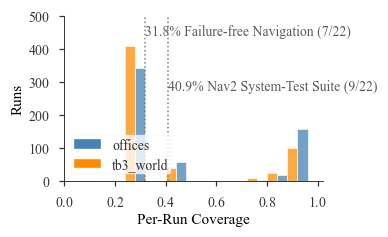

In [8]:
# ---- Figure 2: per-run coverage distribution, offices vs hexagon (paper fig:detail) ----
# seaborn histplot with multiple="dodge" lays the two campaigns' bars side by side.
detail_hex_runs, _detail_hex_reached, _detail_hex_den = per_run_frame("nav_to_pose_hexagon")

_hist_df = pd.concat([
    detail_hex_runs[["coverage"]].assign(campaign="tb3_world"),
    detail_runs[["coverage"]].assign(campaign="offices"),
])

fig, ax = plt.subplots(figsize=(SINGLE_COLUMN, 2.2))
sns.histplot(data=_hist_df, x="coverage", hue="campaign", bins=np.arange(0, 1.001, 0.08),
             multiple="dodge", shrink=1.0, edgecolor="white", lw=0.4,
             palette={"offices": "steelblue", "tb3_world": "darkorange"})
ax.set_xlim(0, 1.02)
ax.axvline(0.318, ls=":", c="grey", lw=1.0)
ax.text(0.318, ax.get_ylim()[1]*0.95, "31.8% Failure-free Navigation (7/22)", fontsize=9,
        color="0.35", va="top", ha="left")
_suite_baseline = 9/22
ax.axvline(_suite_baseline, ls=":", c="grey", lw=1.0)
ax.text(_suite_baseline, ax.get_ylim()[1]*0.62, "40.9% Nav2 System-Test Suite (9/22)", fontsize=9,
        color="0.35", va="top", ha="left")
ax.set_xlabel("Per-Run Coverage", fontsize=10)
ax.set_ylabel("Runs", fontsize=10)
ax.tick_params(labelsize=9)

from matplotlib.patches import Patch
legend_handles = [
    Patch(facecolor="steelblue", edgecolor="white", label="offices"),
    Patch(facecolor="darkorange", edgecolor="white", label="tb3_world"),
]

ax.legend(
    handles=legend_handles,
    fontsize=9,
    frameon=True,
    loc="lower left",
)
# ax.legend(labels=["offices", "tb3_world"], fontsize=9, frameon=True, loc="lower left")

# ax = axs[1]
# batch_of = dict(zip(zip(detail_runs["config_name"], detail_runs["run_id"]),
#                     detail_runs["batch"]))
# union, rows_cum = set(), []
# for bag, rm in detail_reached.items():
#     p = Path(bag); b = batch_of.get((p.parents[1].name, int(p.parent.name)))
#     if b is None:
#         continue
#     union |= set(rm) & TREES[DETAIL_NAME]["declared"]
#     rows_cum.append((b, len(union)))
# cum = pd.DataFrame(rows_cum, columns=["batch", "n"]).groupby("batch")["n"].max()
# ax.plot(cum.index, cum.values, marker="o", ms=3, ls="-", color="seagreen",
#         label="Distinct nodes covered (union)")
# ax.axhline(detail_den, ls="--", c="grey", lw=0.8)
# ax.text(0.0, detail_den + 1.0, f"All {detail_den} Declared Nodes", fontsize=7, color="grey")
# ax.set_xlabel("Batch", fontsize=8)
# ax.set_ylabel("Nodes Covered", fontsize=8)
# ax.set_ylim(0, detail_den + 2.5)
# ax.tick_params(labelsize=7)
# ax.set_title("Distinct Nodes Covered by Any Run (Cumulative Union)", fontsize=9)

# axm = ax.twinx()
# mb = detail_runs.groupby("batch")["coverage"].mean()
# axm.plot(mb.index, mb.values, marker="o", ms=3, ls="--", lw=1.0, color="0.35",
#          label="Mean per-run coverage")
# axm.set_ylim(0, 1)
# axm.set_ylabel("Mean Per-Run Coverage", fontsize=6.5, color="0.35")
# axm.tick_params(labelsize=6, colors="0.35")
# labels = [l.get_label() for l in (ax.get_lines() + axm.get_lines()) if l.get_label()]
# ax.legend([l for l in (ax.get_lines() + axm.get_lines()) if l.get_label()],
#           labels, loc="lower center", fontsize=6.5, frameon=True)

fig.tight_layout()
fout = DATA_ROOT / "fig2_distribution.png"
fig.savefig(fout, dpi=800, bbox_inches="tight")
print(f"saved: {fout}")
plt.show()


random offices: 120 scenarios, mean coverage = 0.415
random tb3_world: 116 scenarios, mean coverage = 0.455
qd offices: 119 scenarios, mean coverage = 0.532
qd tb3_world: 118 scenarios, mean coverage = 0.463


saved: /home/sam/Downloads/ICRA analysis/fig2_distribution_w_random.png


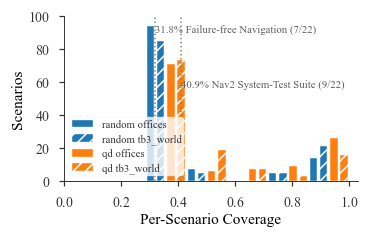

In [9]:
# ---- Figure: per-SCENARIO coverage distribution, random vs QD nav_to_pose ----
# Each scenario (concrete configuration) contributes its mean coverage over its runs.
# Color = random (blue) vs QD (orange); fill = offices (solid) vs tb3_world (striped).
# Random groups are drawn before the QD groups. Original Figure 2 cell is untouched.
import csv as _csv

RND_CAMPAIGNS = {
    "random offices": DATA_ROOT / "truely_random" / "random-secorolab-nav-to-pose-2026-09-16-22024739.incomplete" \
                      / "random-secorolab-nav-to-pose-2026-09-16-22024739",
    "random tb3_world": DATA_ROOT / "truely_random" / "random-hexagon-nav-to-pose-2026-09-16-20142397",
}

def random_runs_frame(root):
    rows = []
    for cfg in sorted(d for d in root.iterdir() if d.is_dir() and d.name.startswith("tr-")):
        bc = cfg / "0" / "bt_coverage.csv"
        if not bc.exists():
            continue
        with open(bc) as f:
            r = next(_csv.DictReader(f))
        rows.append(dict(config_name=cfg.name,
                         coverage=int(r["nodes_reached"]) / int(r["nodes_total"])))
    return pd.DataFrame(rows)

def scenario_frame(runs):
    """One scenario = mean coverage of its runs (1 run for random, 5 reps for QD)."""
    return runs.groupby("config_name")["coverage"].mean().reset_index()

sc = {}
sc["random offices"]   = random_runs_frame(RND_CAMPAIGNS["random offices"])
sc["random tb3_world"] = random_runs_frame(RND_CAMPAIGNS["random tb3_world"])
sc["qd offices"]       = scenario_frame(detail_runs)
sc["qd tb3_world"]     = scenario_frame(detail_hex_runs)
for label, fr in sc.items():
    print(f"{label}: {len(fr)} scenarios, mean coverage = {fr['coverage'].mean():.3f}")

# order: random first, then QD; color per family, hatch per map
order   = ["random offices", "random tb3_world", "qd offices", "qd tb3_world"]
colors  = {"random": "tab:blue", "qd": "tab:orange"}
hatches = {"offices": None, "tb3_world": "///"}

_edges  = np.linspace(0, 1, 8)
_cents  = (_edges[:-1] + _edges[1:]) / 2
_bw     = np.diff(_edges)[0] / len(order)          # inter-group spacing
_width  = _bw * 0.72                               # thin columns
_offs   = (np.arange(len(order)) - (len(order) - 1) / 2) * _bw

fig, ax = plt.subplots(figsize=(SINGLE_COLUMN, 2.2))
for i, label in enumerate(order):
    family, mapname = label.split(" ", 1)
    vals = np.clip(sc[label]["coverage"].values, 0, 0.9999)
    counts, _ = np.histogram(vals, bins=_edges)
    ax.bar(_cents + _offs[i], counts, width=_width,
           facecolor=colors[family], hatch=hatches[mapname],
           edgecolor="white", lw=0.3, align="center")

ax.set_xlim(0, 1.03)
ax.axvline(0.318, ls=":", c="grey", lw=1.0)
ax.text(0.318, ax.get_ylim()[1]*0.95, "31.8% Failure-free Navigation (7/22)", fontsize=7,
        color="0.35", va="top", ha="left")
_suite_baseline = 9/22
ax.axvline(_suite_baseline, ls=":", c="grey", lw=1.0)
ax.text(_suite_baseline, ax.get_ylim()[1]*0.62, "40.9% Nav2 System-Test Suite (9/22)", fontsize=7,
        color="0.35", va="top", ha="left")
ax.set_xlabel("Per-Scenario Coverage", fontsize=10)
ax.set_ylabel("Scenarios", fontsize=10)
ax.tick_params(labelsize=9)

from matplotlib.patches import Patch
legend_handles = [Patch(facecolor=colors[l.split(" ", 1)[0]], hatch=hatches[l.split(" ", 1)[1]],
                        edgecolor="white", label=l) for l in order]
ax.legend(handles=legend_handles, fontsize=7, frameon=True, loc="lower left")

fig.tight_layout()
fout = DATA_ROOT / "fig2_distribution_w_random.png"
fig.savefig(fout, dpi=800, bbox_inches="tight")
print(f"saved: {fout}")
plt.show()

random offices: 120 scenarios, mean coverage = 0.415
random tb3_world: 116 scenarios, mean coverage = 0.455
qd offices: 119 scenarios, mean coverage = 0.532
qd tb3_world: 118 scenarios, mean coverage = 0.463
saved: /home/sam/Downloads/ICRA analysis/fig2_ecdf_w_random.png


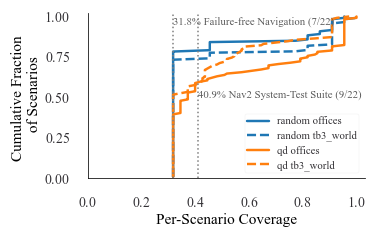

In [337]:
# ---- Figure: per-scenario coverage ECDF, random vs QD nav_to_pose (line version) ----
# Empirical cumulative distribution: no binning, no dodging -- one clean line per campaign.
# Color = random (blue) vs QD (orange); line style = offices (solid) vs tb3_world (dashed).
# Original histogram cell is untouched -- this is a separate copy.
import csv as _csv

RND_CAMPAIGNS = {
    "random offices": DATA_ROOT / "truely_random" / "random-secorolab-nav-to-pose-2026-09-16-22024739.incomplete" \
                      / "random-secorolab-nav-to-pose-2026-09-16-22024739",
    "random tb3_world": DATA_ROOT / "truely_random" / "random-hexagon-nav-to-pose-2026-09-16-20142397",
}

def random_runs_frame(root):
    rows = []
    for cfg in sorted(d for d in root.iterdir() if d.is_dir() and d.name.startswith("tr-")):
        bc = cfg / "0" / "bt_coverage.csv"
        if not bc.exists():
            continue
        with open(bc) as f:
            r = next(_csv.DictReader(f))
        rows.append(dict(config_name=cfg.name,
                         coverage=int(r["nodes_reached"]) / int(r["nodes_total"])))
    return pd.DataFrame(rows)

def scenario_frame(runs):
    """One scenario = mean coverage of its runs (1 run for random, 5 reps for QD)."""
    return runs.groupby("config_name")["coverage"].mean().reset_index()

def ecdf(values):
    v = np.sort(values)
    return v, np.arange(1, len(v) + 1) / len(v)

sc = {}
sc["random offices"]   = random_runs_frame(RND_CAMPAIGNS["random offices"])
sc["random tb3_world"] = random_runs_frame(RND_CAMPAIGNS["random tb3_world"])
sc["qd offices"]       = scenario_frame(detail_runs)
sc["qd tb3_world"]     = scenario_frame(detail_hex_runs)
for label, fr in sc.items():
    print(f"{label}: {len(fr)} scenarios, mean coverage = {fr['coverage'].mean():.3f}")

order   = ["random offices", "random tb3_world", "qd offices", "qd tb3_world"]
col     = {"random": "tab:blue", "qd": "tab:orange"}
lss     = {"offices": "-", "tb3_world": "--"}

fig, ax = plt.subplots(figsize=(SINGLE_COLUMN, 2.2))
for label in order:
    family, mapname = label.split(" ", 1)
    v, y = ecdf(sc[label]["coverage"].values)
    ax.plot(v, y, color=col[family], ls=lss[mapname], lw=1.6, label=label)

ax.set_xlim(0, 1.03)
ax.set_ylim(0, 1.02)
ax.axvline(0.318, ls=":", c="grey", lw=1.0)
ax.text(0.318, 1.0, "31.8% Failure-free Navigation (7/22)", fontsize=7,
        color="0.35", va="top", ha="left")
_suite_baseline = 9/22
ax.axvline(_suite_baseline, ls=":", c="grey", lw=1.0)
ax.text(_suite_baseline, 0.55, "40.9% Nav2 System-Test Suite (9/22)", fontsize=7,
        color="0.35", va="top", ha="left")
ax.set_xlabel("Per-Scenario Coverage", fontsize=10)
ax.set_ylabel("Cumulative Fraction \n of Scenarios", fontsize=10)
ax.tick_params(labelsize=9)
ax.legend(fontsize=7, frameon=True, loc="lower right")

fig.tight_layout()
fout = DATA_ROOT / "fig2_ecdf_w_random.png"
fig.savefig(fout, dpi=800, bbox_inches="tight")
print(f"saved: {fout}")
plt.show()

saved: /home/sam/Downloads/ICRA analysis/fig1_qd_vs_random.png  (baseline=0.409, QD band min=0.318, random mean=0.415, random best=0.955)


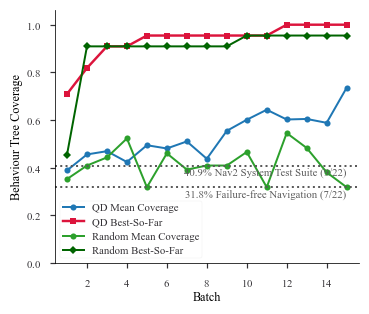

In [11]:
NAME = "nav_to_pose_secorolab"
TITLE = "Coverage over Batches Using nav_to_pose on the offices Map"
RND_ROOT = DATA_ROOT / "truely_random" / "random-secorolab-nav-to-pose-2026-09-16-22024739.incomplete" \
           / "random-secorolab-nav-to-pose-2026-09-16-22024739"

import csv as _csv

def _random_run_coverages():
    """Per-run coverage of the random-secorolab runs, in run order."""
    vals = []
    for i in range(120):
        cp = RND_ROOT / f"tr-{i:03d}" / "0" / "bt_coverage.csv"
        if cp.exists():
            with open(cp) as f:
                row = next(_csv.DictReader(f))
            vals.append(int(row["nodes_reached"]) / int(row["nodes_total"]))
    return vals

def _random_batch_stats(vals, size=8):
    """Aggregate the random runs in groups of 8 (mean and max) so the 15 values
    line up with the 15 batches of the QD campaign."""
    means = [float(np.mean(vals[i:i + size])) for i in range(0, len(vals), size)]
    maxes = [float(np.max(vals[i:i + size])) for i in range(0, len(vals), size)]
    return means, maxes

fig, ax = plt.subplots(figsize=(SINGLE_COLUMN, 2.9))
u = campaigns[NAME]["units"].dropna(subset=["objective"]).copy()
perf = u.groupby("batch")["objective"].agg(["mean", "min", "max"])
best = perf["max"].cummax()
x = perf.index + 1
rnd_mean, rnd_batch_max = _random_batch_stats(_random_run_coverages())
rnd_best = np.maximum.accumulate(rnd_batch_max)

# ax.fill_between(x, perf["min"].values, perf["max"].values,
#                 color="lightsteelblue", alpha=0.55, lw=0,
#                 label="QD Min–Max Coverage")
ax.plot(x, perf["mean"].values, marker="o", ms=4, ls="-",
        color="tab:blue", lw=1.3, label="QD Mean Coverage")
ax.plot(x, best.values, marker="s", ms=4, ls="-", color="crimson", lw=1.6,
        label="QD Best-So-Far")
ax.plot(x, rnd_mean, marker="o", ms=4, ls="-", color="tab:green", lw=1.3,
        label="Random Mean Coverage")
ax.plot(x, rnd_best, marker="D", ms=4, ls="-", color="darkgreen", lw=1.3,
        label="Random Best-So-Far")
ax.axhline(BASELINE, ls=":", c="0.35", lw=1.3)
ax.text(x[-1], BASELINE - 0.008, f"{100*BASELINE:.1f}% Nav2 System Test Suite (9/22)", ha="right",
        va="top", fontsize=7, color="0.35")
ax.axhline(0.318, ls=":", c="0.35", lw=1.3)
ax.text(x[-1], 0.318 - 0.008, f"{100*0.318:.1f}% Failure-free Navigation (7/22)", ha="right",
        va="top", fontsize=7, color="0.35")

ax.set_ylim(0, 1.06)
ax.set_xlim(0.4, 15.6)
ax.set_xlabel("Batch", fontsize=8)
ax.set_ylabel("Behaviour Tree Coverage", fontsize=8)
ax.tick_params(labelsize=7)
ax.legend(fontsize=7, loc="lower left", frameon=True, ncol=1)
fig.tight_layout()
fout = DATA_ROOT / "fig1_qd_vs_random.png"
fig.savefig(fout, dpi=300, bbox_inches="tight")
print(f"saved: {fout}  (baseline={BASELINE:.3f}, QD band min={perf['min'].min():.3f}, "
      f"random mean={np.mean(rnd_mean):.3f}, random best={rnd_best[-1]:.3f})")
plt.show()

## Reading Figure 2

The two panels measure different things, so they do **not** conflict with Figure 1 or with
each other. **Figure 1** tracks per-run coverage over the batches: best-so-far rises from
0.709 in batch 0 to 1.0 by batch 12. The **top panel** here shows the distribution of all
595 per-run coverages: it is strongly **bimodal** \--- 342 runs sit exactly on the
clean-navigation floor 7/22 = 0.318 (no recovery node fired), while the remaining 253 runs
cluster at 0.9 or above. The **bottom panel** shows the *union* of declared nodes covered
by at least one run. Across a batch's diverse configurations (some reach only the core,
others nearly everything) the union already spans all 22 declared nodes in batch 0. That
completeness is a statement of **node reachability** within the scenario space; it is the
per-run *completeness* --- how often each reachable node fires --- that the later batches
push toward 1.0. Later batches therefore add no new nodes; they raise how often each
already-reachable node is activated.


## Figure 3: nav_to_pose behaviour tree, reached vs never reached

Two stacked diagrams of the same 22-node behaviour tree (paper Fig.~\ref{fig:node}): the
stock **Nav2 system-test suite** on top and the **nav_to_pose offices QD campaign**
below. Node fill is binary: green = the node was activated by at least one run, red =
never activated. The node border encodes node type (Control, Recovery-wrapped,
recovery actions, Clear*Costmap, Condition).

* **Nav2 system-test suite** (70 runs): only 7 of 22 nodes are ever activated --- the
  clean-navigation spine --- the whole recovery subtree stays red.
* **nav_to_pose offices** (595 runs): all 22 nodes are reached; every node turns green.


saved: /home/sam/Downloads/ICRA analysis/fig3_btrees.png  (baseline 7/22, QD 22/22)


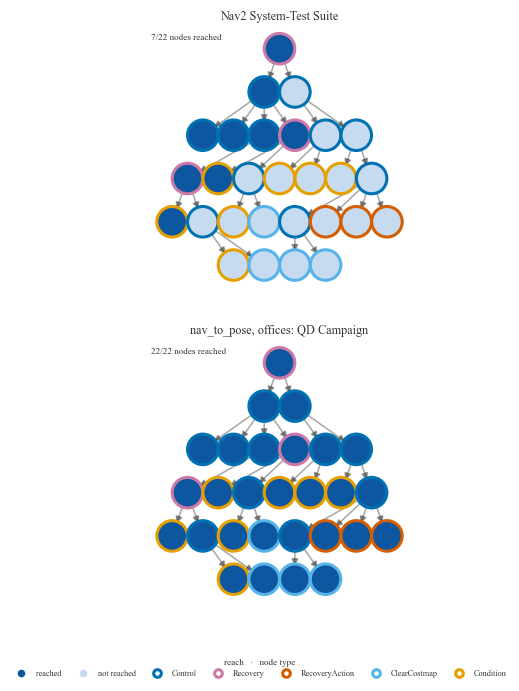

In [12]:
# ---- Figure 3: nav_to_pose BT, reached vs never reached (Nav2 system-test suite vs QD) ----
# node fill: reached in >=1 run -> dark blue, never reached -> light gray; node border: node type.
import csv as _csv
from matplotlib.lines import Line2D
import networkx as nx

def baseline_reached_set():
    """Declared nodes ever reached by the stock Nav2 system-test suite (nav_to_pose tree runs)."""
    rows_by_run = []
    for p in SYSTEM_ROOT.rglob("nav2_behaviors.csv"):
        if not p.parent.name.isdigit():
            continue
        with open(p) as fh:
            rows = list(_csv.DictReader(fh))
        nm = {r["behavior_name"] for r in rows}
        if "ComputePathToPose" in nm and "NavigateThroughPoses" not in nm:
            rows_by_run.append(rows)
    out = set()
    for rows in rows_by_run:
        last = {}
        for r in rows:
            if r["behavior_name"]:
                last[r["behavior_name"]] = r["status_name"]
        out |= {b for b, s in last.items() if s not in ("IDLE", "INVALID", "")}
    return out

def campaign_reached_set(name):
    """Declared nodes ever reached across a campaign's runs."""
    out = set()
    for rm in load_reached(name).values():
        out |= set(rm)
    return out

EDGE_TYPES = {
    "Control": "#0072b2",
    "Recovery": "#cc79a7",
    "RecoveryAction": "#d55e00",
    "ClearCostmap": "#56b4e9",
    "Condition": "#e69f00",
}

def node_type(tag, name):
    if tag in ("Sequence", "Fallback", "ReactiveFallback", "PipelineSequence", "RoundRobin",
               "ControllerSelector", "PlannerSelector", "RateController"):
        return "Control"
    if tag == "RecoveryNode":
        return "Recovery"
    if tag == "ClearEntireCostmap":
        return "ClearCostmap"
    if name in ("Spin", "Wait", "BackUp"):
        return "RecoveryAction"
    return "Condition"

def _tree_pos(names, parents):
    """Coverage-notebook layout: nodes packed per depth row, centered on the column."""
    from collections import defaultdict
    children, roots = defaultdict(list), []
    for i, p in parents.items():
        (roots if p is None else children[p]).append(i)
    depth = {}
    def dfs(i, d):
        depth[i] = d
        for j in children[i]:
            dfs(j, d + 1)
    for r in roots:
        dfs(r, 0)
    layers = defaultdict(list)
    for i in range(len(names)):
        layers[depth[i]].append(i)
    pos = {}
    for d, members in layers.items():
        m = len(members)
        for k, i in enumerate(members):
            pos[i] = (k - (m - 1) / 2, -d * 1.6)
    return pos

def draw_binary_tree(ax, name, reached_set):
    t = parse_bt_xml(TREES[name]["xml_path"])
    pos = _tree_pos(t["names"], t["parents"])
    G = nx.DiGraph()
    G.add_edges_from((p, i) for i, p in t["parents"].items() if p is not None)
    cmap = plt.get_cmap("Blues")
    colors = [cmap(0.85 if nm in reached_set else 0.25) for nm in t["names"]]
    ecols = [EDGE_TYPES[node_type(t["classes"][i], t["names"][i])] for i in range(len(t["names"]))]
    nx.draw_networkx_edges(G, pos, ax=ax, alpha=0.35, arrows=True, arrowsize=9)
    nx.draw_networkx_nodes(G, pos, ax=ax, node_color=colors, node_size=400,
                           edgecolors=ecols, linewidths=2.0)
    declared = TREES[name]["declared"]
    reached = sum(1 for d in declared if d in reached_set)
    ax.text(0.005, 0.97, f"{reached}/{len(declared)} nodes reached",
            transform=ax.transAxes, fontsize=6, va="top", color="0.2")
    ax.set_xticks([]); ax.set_yticks([])
    for s in ax.spines.values():
        s.set_visible(False)

bl = baseline_reached_set()
qd = campaign_reached_set("nav_to_pose_secorolab")

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(SINGLE_COLUMN, 6.8))
ax1.set_title("Nav2 System-Test Suite", fontsize=8, pad=4)
draw_binary_tree(ax1, "nav_to_pose_secorolab", bl)
ax2.set_title("nav_to_pose, offices: QD Campaign", fontsize=8, pad=4)
draw_binary_tree(ax2, "nav_to_pose_secorolab", qd)
fig.subplots_adjust(right=0.82)

fill_patches = [Line2D([0], [0], marker="o", color="none",
                       markerfacecolor=plt.get_cmap("Blues")(v),
                       markeredgecolor="0.4", markersize=5, label=l)
                for v, l in ((0.85, "reached"), (0.25, "not reached"))]
type_patches = [Line2D([0], [0], marker="o", color="none", markerfacecolor="white",
                       markeredgecolor=c, markeredgewidth=2.0, markersize=5, label=k)
                for k, c in EDGE_TYPES.items()]
fig.legend(handles=fill_patches + type_patches, loc="lower center", ncol=7,
           bbox_to_anchor=(0.42, 0.0), fontsize=5.5, frameon=False,
           title="reach   \u00b7   node type", title_fontsize=6)

fout = DATA_ROOT / "fig3_btrees.png"
fig.savefig(fout, dpi=300, bbox_inches="tight")
print(f"saved: {fout}  (baseline "
      f"{len(bl & TREES['nav_to_pose_secorolab']['declared'])}/22, QD "
      f"{len(qd & TREES['nav_to_pose_secorolab']['declared'])}/22)")
plt.show()

saved: /home/sam/Downloads/ICRA analysis/fig3_btrees_sidebyside.png


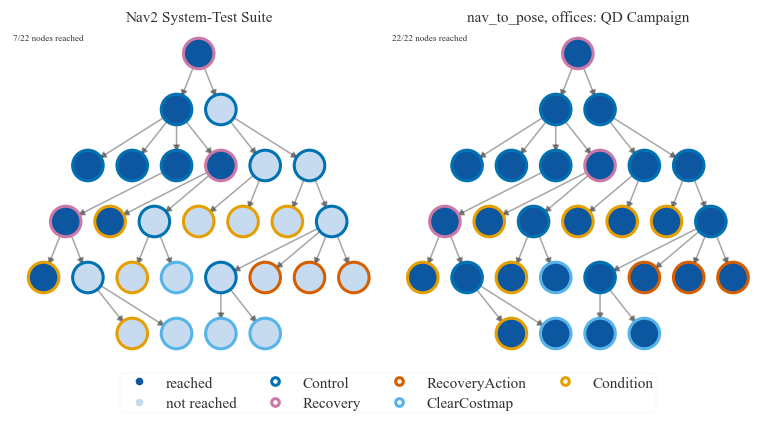

In [13]:
# ---- Figure 3 (side-by-side variant): nav_to_pose BT, Nav2 system-test suite vs QD campaign ----
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(TWO_COLUMNS, 3.5))
ax1.set_title("Nav2 System-Test Suite", fontsize=10, pad=1)
draw_binary_tree(ax1, "nav_to_pose_secorolab", bl)
ax2.set_title("nav_to_pose, offices: QD Campaign", fontsize=10, pad=1)
draw_binary_tree(ax2, "nav_to_pose_secorolab", qd)
fig.subplots_adjust(left=0.01, right=0.99, top=0.93, bottom=0.05, wspace=0.01)

fill_patches = [Line2D([0], [0], marker="o", color="none",
                       markerfacecolor=plt.get_cmap("Blues")(v),
                       markeredgecolor="0.4", markersize=5, label=l)
                for v, l in ((0.85, "reached"), (0.25, "not reached"))]
type_patches = [Line2D([0], [0], marker="o", color="none", markerfacecolor="white",
                       markeredgecolor=c, markeredgewidth=2.0, markersize=5, label=k)
                for k, c in EDGE_TYPES.items()]
fig.legend(handles=fill_patches + type_patches, loc="lower center", ncol=4,
           bbox_to_anchor=(0.5, -0.1), fontsize=10, frameon=True,)

fout = DATA_ROOT / "fig3_btrees_sidebyside.png"
fig.savefig(fout, dpi=300, bbox_inches="tight")
print(f"saved: {fout}")
plt.show()


saved: /home/sam/Downloads/ICRA analysis/fig3_btrees_edgecontrast.png


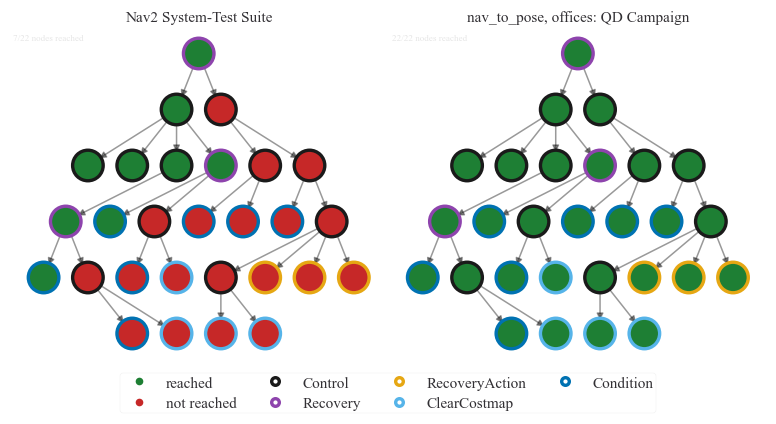

In [14]:
# ---- Figure 3 (variant A): same side-by-side trees; node fills red/green (not reached / reached);
#      node borders recolored for maximum contrast against red and green fills
#      (colorblind-safe palette: near-black, violet, amber, two blues; no red/green) ----
from matplotlib.lines import Line2D

NEW_EDGE_TYPES = {
    "Control": "#1a1a1a",        # near-black
    "Recovery": "#8e44ad",       # violet
    "RecoveryAction": "#e6a713", # amber/orange
    "ClearCostmap": "#56b4e9",   # sky blue
    "Condition": "#0072b2",      # strong blue
}
REACHED_C = "#1e7f34"    # green fill  = node reached in >=1 run
UNREACHED_C = "#c62828"  # red fill    = node never reached

def node_fill(nm, reached_set):
    return REACHED_C if nm in reached_set else UNREACHED_C

def draw_binary_tree_ec(ax, name, reached_set):
    t = parse_bt_xml(TREES[name]["xml_path"])
    pos = _tree_pos(t["names"], t["parents"])
    G = nx.DiGraph()
    G.add_edges_from((p, i) for i, p in t["parents"].items() if p is not None)
    colors = [node_fill(nm, reached_set) for nm in t["names"]]
    ecols = [NEW_EDGE_TYPES[node_type(t["classes"][i], t["names"][i])]
             for i in range(len(t["names"]))]
    nx.draw_networkx_edges(G, pos, ax=ax, alpha=0.4, arrows=True, arrowsize=9)
    nx.draw_networkx_nodes(G, pos, ax=ax, node_color=colors, node_size=400,
                           edgecolors=ecols, linewidths=2.2)
    declared = TREES[name]["declared"]
    reached = sum(1 for d in declared if d in reached_set)
    ax.text(0.005, 0.97, f"{reached}/{len(declared)} nodes reached",
            transform=ax.transAxes, fontsize=6, va="top", color="0.9")
    ax.set_xticks([]); ax.set_yticks([])
    for s in ax.spines.values():
        s.set_visible(False)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(TWO_COLUMNS, 3.5))
ax1.set_title("Nav2 System-Test Suite", fontsize=10, pad=1)
draw_binary_tree_ec(ax1, "nav_to_pose_secorolab", bl)
ax2.set_title("nav_to_pose, offices: QD Campaign", fontsize=10, pad=1)
draw_binary_tree_ec(ax2, "nav_to_pose_secorolab", qd)
fig.subplots_adjust(left=0.01, right=0.99, top=0.93, bottom=0.05, wspace=0.01)

fill_patches = [Line2D([0], [0], marker="o", color="none",
                       markerfacecolor=c, markeredgecolor="0.4", markersize=5, label=l)
                for c, l in ((REACHED_C, "reached"), (UNREACHED_C, "not reached"))]
type_patches = [Line2D([0], [0], marker="o", color="none", markerfacecolor="white",
                       markeredgecolor=c, markeredgewidth=2.2, markersize=5, label=k)
                for k, c in NEW_EDGE_TYPES.items()]
fig.legend(handles=fill_patches + type_patches, loc="lower center", ncol=4,
           bbox_to_anchor=(0.5, -0.1), fontsize=10, frameon=True)

fout = DATA_ROOT / "fig3_btrees_edgecontrast.png"
fig.savefig(fout, dpi=300, bbox_inches="tight")
print(f"saved: {fout}")
plt.show()


saved: /home/sam/Downloads/ICRA analysis/fig3_btrees_numbered.png


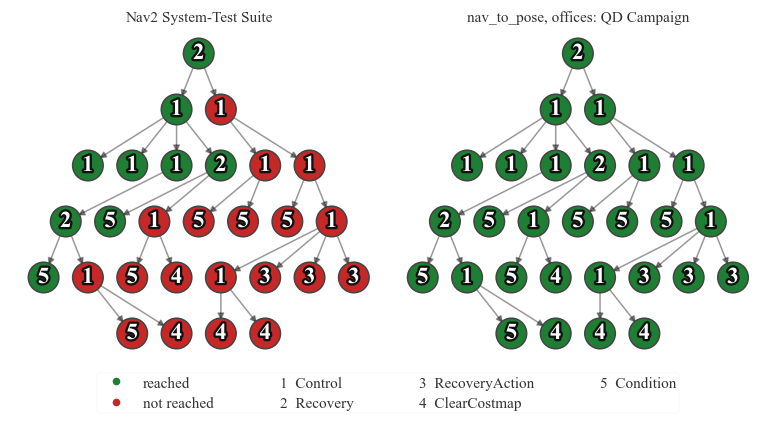

node-type counts in nav_to_pose tree:
  1. Control: 11
  2. Recovery: 3
  3. RecoveryAction: 3
  4. ClearCostmap: 4
  5. Condition: 7


In [15]:
# ---- Figure 3 (variant B): same side-by-side trees; node fills red/green (not reached / reached);
#      borders are uniformly neutral (encode nothing); the NUMBER inside each node encodes its type ----
from matplotlib.lines import Line2D
from matplotlib import patheffects
from collections import Counter

REACHED_C = "#1e7f34"    # green fill  = node reached in >=1 run
UNREACHED_C = "#c62828"  # red fill    = node never reached
TYPE_NUMBER = {t: i + 1 for i, t in enumerate(
    ("Control", "Recovery", "RecoveryAction", "ClearCostmap", "Condition"))}

def node_fill(nm, reached_set):
    return REACHED_C if nm in reached_set else UNREACHED_C

def draw_binary_tree_nd(ax, name, reached_set):
    t = parse_bt_xml(TREES[name]["xml_path"])
    pos = _tree_pos(t["names"], t["parents"])
    G = nx.DiGraph()
    G.add_edges_from((p, i) for i, p in t["parents"].items() if p is not None)
    colors = [node_fill(nm, reached_set) for nm in t["names"]]
    nx.draw_networkx_edges(G, pos, ax=ax, alpha=0.4, arrows=True, arrowsize=9)
    nx.draw_networkx_nodes(G, pos, ax=ax, node_color=colors, node_size=400,
                           edgecolors="#444444", linewidths=1.0)
    for i in range(len(t["names"])):
        ax.text(pos[i][0], pos[i][1],
                str(TYPE_NUMBER[node_type(t["classes"][i], t["names"][i])]),
                ha="center", va="center", fontsize=15, color="white", fontweight="bold",
                path_effects=[patheffects.withStroke(linewidth=3, foreground="#111111")])
    declared = TREES[name]["declared"]
    reached = sum(1 for d in declared if d in reached_set)
    ax.text(0.005, 0.97, f"{reached}/{len(declared)} nodes reached",
            transform=ax.transAxes, fontsize=6, va="top", color="1.0")
    ax.set_xticks([]); ax.set_yticks([])
    for s in ax.spines.values():
        s.set_visible(False)

_t = parse_bt_xml(TREES["nav_to_pose_secorolab"]["xml_path"])
present = {node_type(_t["classes"][i], _t["names"][i]) for i in range(len(_t["names"]))}

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(TWO_COLUMNS, 3.5))
ax1.set_title("Nav2 System-Test Suite", fontsize=10, pad=1)
draw_binary_tree_nd(ax1, "nav_to_pose_secorolab", bl)
ax2.set_title("nav_to_pose, offices: QD Campaign", fontsize=10, pad=1)
draw_binary_tree_nd(ax2, "nav_to_pose_secorolab", qd)
fig.subplots_adjust(left=0.01, right=0.99, top=0.93, bottom=0.05, wspace=0.01)

fill_patches = [Line2D([0], [0], marker="o", color="none",
                       markerfacecolor=c, markeredgecolor="0.4", markersize=5, label=l)
                for c, l in ((REACHED_C, "reached"), (UNREACHED_C, "not reached"))]
num_patches = [Line2D([0], [0], marker="o", color="none", markerfacecolor="white",
                      markeredgecolor="0.35", markersize=5, label=f"{n}  {k}")
               for k, n in sorted(TYPE_NUMBER.items(), key=lambda kv: kv[1]) if k in present]
fig.legend(handles=fill_patches + num_patches, loc="lower center", ncol=4,
           bbox_to_anchor=(0.5, -0.1), fontsize=10, frameon=True)

fout = DATA_ROOT / "fig3_btrees_numbered.png"
fig.savefig(fout, dpi=300, bbox_inches="tight")
print(f"saved: {fout}")
plt.show()

cnt = Counter(node_type(_t["classes"][i], _t["names"][i]) for i in range(len(_t["names"])))
print("node-type counts in nav_to_pose tree:")
for k, n in sorted(TYPE_NUMBER.items(), key=lambda kv: kv[1]):
    print(f"  {n}. {k}: {cnt.get(k, 0)}")


saved: /home/sam/Downloads/ICRA analysis/fig3_btree_numbered_suite.png


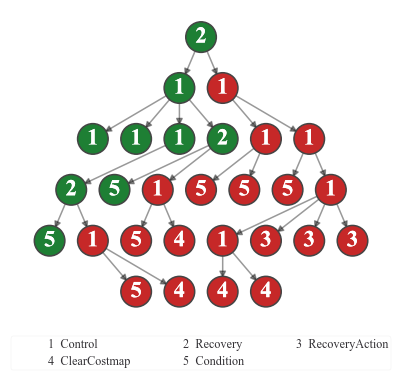

In [16]:
# ---- Figure 3 (variant B, suite tree only): nav_to_pose BT, Nav2 system-test suite ----
# Same tree as the left panel of the side-by-side variant; no title; legend in 2 columns (4 rows).
from matplotlib.lines import Line2D
from matplotlib import patheffects
from collections import Counter

REACHED_C = "#1e7f34"    # green fill  = node reached in >=1 run
UNREACHED_C = "#c62828"  # red fill    = node never reached
TYPE_NUMBER = {t: i + 1 for i, t in enumerate(
    ("Control", "Recovery", "RecoveryAction", "ClearCostmap", "Condition"))}

def node_fill(nm, reached_set):
    return REACHED_C if nm in reached_set else UNREACHED_C

def draw_binary_tree_nd(ax, name, reached_set):
    t = parse_bt_xml(TREES[name]["xml_path"])
    pos = _tree_pos(t["names"], t["parents"])
    G = nx.DiGraph()
    G.add_edges_from((p, i) for i, p in t["parents"].items() if p is not None)
    colors = [node_fill(nm, reached_set) for nm in t["names"]]
    nx.draw_networkx_edges(G, pos, ax=ax, alpha=0.4, arrows=True, arrowsize=9)
    nx.draw_networkx_nodes(G, pos, ax=ax, node_color=colors, node_size=400,
                           edgecolors="#444444", linewidths=1.0)
    for i in range(len(t["names"])):
        ax.text(pos[i][0], pos[i][1],
                str(TYPE_NUMBER[node_type(t["classes"][i], t["names"][i])]),
                ha="center", va="center", fontsize=15, color="white", fontweight="bold",
                path_effects=[patheffects.withStroke(linewidth=0, foreground="#111111")])
    declared = TREES[name]["declared"]
    reached = sum(1 for d in declared if d in reached_set)
    ax.text(0.005, 0.97, f"{reached}/{len(declared)} nodes reached",
            transform=ax.transAxes, fontsize=6, va="top", color="1.0")
    ax.set_xticks([]); ax.set_yticks([])
    for s in ax.spines.values():
        s.set_visible(False)

_t = parse_bt_xml(TREES["nav_to_pose_secorolab"]["xml_path"])
present = {node_type(_t["classes"][i], _t["names"][i]) for i in range(len(_t["names"]))}

fig, ax = plt.subplots(figsize=(SINGLE_COLUMN, 3.5))
draw_binary_tree_nd(ax, "nav_to_pose_secorolab", bl)
fig.subplots_adjust(left=0.01, right=0.99, top=0.99, bottom=0.19)

fill_patches = [Line2D([0], [0], marker="o", color="none",
                       markerfacecolor=c, markeredgecolor="0.4", markersize=5, label=l)
                for c, l in ((REACHED_C, "reached"), (UNREACHED_C, "not reached"))]
num_patches = [Line2D([0], [0], marker="o", color="none", markerfacecolor="white",
                      markeredgecolor="0.35", markersize=5, label=f"{n}  {k}")
               for k, n in sorted(TYPE_NUMBER.items(), key=lambda kv: kv[1]) if k in present]
# ncol=3 fills column-major; permute so the legend reads row-major:
#   row1: 1 Control | 2 Recovery | 3 RecoveryAction
#   row2: 4 ClearCostmap | 5 Condition | reached
#   row3: not reached
_desired = list(num_patches) + list(fill_patches)
_perm = [0, 3, 1, 4, 2]
fig.legend(handles=[_desired[i] for i in _perm], loc="lower center", ncol=3,
           bbox_to_anchor=(0.5, 0.04), fontsize=8, frameon=True)

fout = DATA_ROOT / "fig3_btree_numbered_suite.png"
fig.savefig(fout, dpi=600, bbox_inches="tight")
print(f"saved: {fout}")
plt.show()


saved: /home/sam/Downloads/ICRA analysis/fig3_btree_numbered_offices_vs_hexagon.png


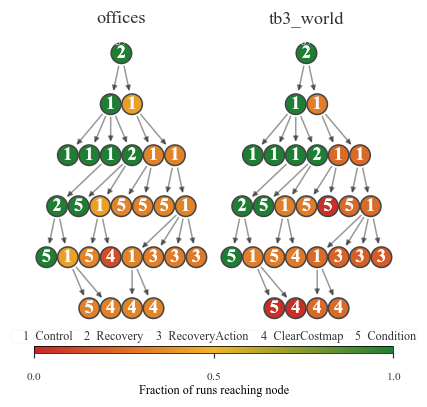

In [17]:
# ---- Figure 3 (variant C): nav_to_pose BT, offices QD campaign vs hexagon QD campaign ----
# Node fill scales with the per-run reach FRACTION (red = never reached, green = reached in
# every run); node TYPE -> number inside the node. Bottom colorbar + type-number legend.
from matplotlib.lines import Line2D
from matplotlib import patheffects
from matplotlib.colors import LinearSegmentedColormap, Normalize
import matplotlib.cm as mcm

TYPE_NUMBER = {t: i + 1 for i, t in enumerate(
    ("Control", "Recovery", "RecoveryAction", "ClearCostmap", "Condition"))}
REACH_CMAP = LinearSegmentedColormap.from_list("reachfrac", ["#c62828", "#f0b429", "#1e7f34"])

def node_frac_map(name):
    """node -> fraction of runs in the campaign that reached it."""
    reached = load_reached(name)
    n = max(len(reached), 1)
    cnt = {}
    for rm in reached.values():
        for node in rm:
            cnt[node] = cnt.get(node, 0) + 1
    return {k: v / n for k, v in cnt.items()}

def draw_binary_tree_nd(ax, name, fracs):
    t = parse_bt_xml(TREES[name]["xml_path"])
    pos = _tree_pos(t["names"], t["parents"])
    G = nx.DiGraph()
    G.add_edges_from((p, i) for i, p in t["parents"].items() if p is not None)
    norm_f = [Normalize(0, 1)(fracs.get(nm, 0.0)) for nm in t["names"]]
    colors = [REACH_CMAP(f) for f in norm_f]
    nx.draw_networkx_edges(G, pos, ax=ax, alpha=0.4, arrows=True, arrowsize=7)
    nx.draw_networkx_nodes(G, pos, ax=ax, node_color=colors, node_size=180,
                           edgecolors="#444444", linewidths=1.0)
    for i in range(len(t["names"])):
        ax.text(pos[i][0], pos[i][1],
                str(TYPE_NUMBER[node_type(t["classes"][i], t["names"][i])]),
                ha="center", va="center", fontsize=12, color="white", fontweight="bold",
                path_effects=[patheffects.withStroke(linewidth=0, foreground="#111111")])
    declared = TREES[name]["declared"]
    avg = float(np.mean([fracs.get(d, 0.0) for d in declared]))
    ax.text(0.005, 0.97, f"avg node reach {avg:.0%}", transform=ax.transAxes,
            fontsize=8, va="top", color="1.0")
    ax.set_xticks([]); ax.set_yticks([])
    for s in ax.spines.values():
        s.set_visible(False)

_fo = node_frac_map("nav_to_pose_secorolab")
_fx = node_frac_map("nav_to_pose_hexagon")
_t = parse_bt_xml(TREES["nav_to_pose_secorolab"]["xml_path"])
present = {node_type(_t["classes"][i], _t["names"][i]) for i in range(len(_t["names"]))}

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(SINGLE_COLUMN, 3.3))
ax1.set_title("offices", fontsize=12, pad=1)
draw_binary_tree_nd(ax1, "nav_to_pose_secorolab", _fo)
ax2.set_title("tb3_world", fontsize=12, pad=1)
draw_binary_tree_nd(ax2, "nav_to_pose_hexagon", _fx)

num_patches = [Line2D([0], [0], marker="o", color="none", markerfacecolor="white",
                      markeredgecolor="0.35", markersize=5, label=f"{n}  {k}")
               for k, n in sorted(TYPE_NUMBER.items(), key=lambda kv: kv[1]) if k in present]
fig.legend(handles=num_patches, loc="lower center", ncol=5,
           bbox_to_anchor=(0.5, 0.03), fontsize=8, frameon=True, columnspacing=0.1,
           handlelength=0.8, handletextpad=0.1, borderpad=0.05, labelspacing=0.1)

cax = fig.add_axes([0.02, 0.02, 0.96, 0.02])
sm = mcm.ScalarMappable(norm=Normalize(0, 1), cmap=REACH_CMAP)
cb = fig.colorbar(sm, cax=cax, orientation="horizontal", ticks=[0, 0.5, 1])
cb.set_label("Fraction of runs reaching node", fontsize=8)
cb.ax.tick_params(labelsize=7.5)
for lab in cb.ax.get_xticklabels():
    lab.set_y(-0.4)

fig.subplots_adjust(left=0.01, right=0.99, top=0.92, bottom=0.07, wspace=0.02)
fout = DATA_ROOT / "fig3_btree_numbered_offices_vs_hexagon.png"
fig.savefig(fout, dpi=300, bbox_inches="tight")
print(f"saved: {fout}")
plt.show()


saved: /home/sam/Downloads/ICRA analysis/fig3_follow_waypoints_variant.png  (secorolab 22/22 · 585 runs, tb3_world 22/22 · 425 runs)


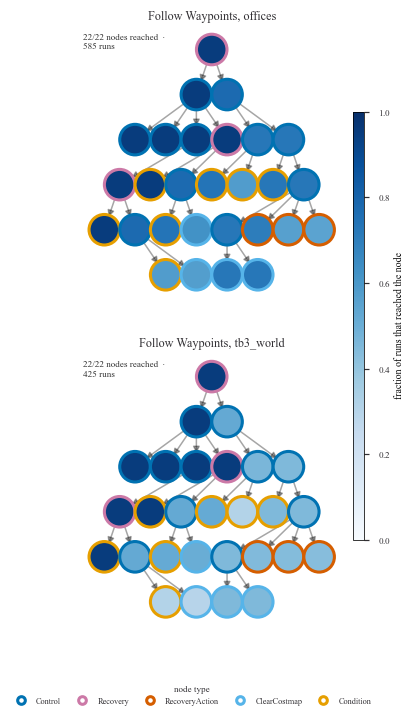

In [18]:
# ---- Figure 3: follow-waypoints BT; node TYPE -> edge colour, run-reach fraction -> fill ----
import networkx as nx
from matplotlib.lines import Line2D

def follow_reach(name):
    """fraction of runs in which each declared node left IDLE."""
    reached = load_reached(name)
    declared = TREES[name]["declared"]
    n = len(reached)
    return {d: sum(1 for rm in reached.values() if d in rm) / n for d in declared}, n

EDGE_TYPES = {
    "Control": "#0072b2",
    "Recovery": "#cc79a7",
    "RecoveryAction": "#d55e00",
    "ClearCostmap": "#56b4e9",
    "Condition": "#e69f00",
}

def node_type(tag, name):
    if tag in ("Sequence", "Fallback", "ReactiveFallback", "PipelineSequence", "RoundRobin",
               "ControllerSelector", "PlannerSelector", "RateController"):
        return "Control"
    if tag == "RecoveryNode":
        return "Recovery"
    if tag == "ClearEntireCostmap":
        return "ClearCostmap"
    if name in ("Spin", "Wait", "BackUp"):
        return "RecoveryAction"
    return "Condition"

def _tree_pos(names, parents):
    """Coverage-notebook layout: nodes packed per depth row, centered on the column."""
    from collections import defaultdict
    children, roots = defaultdict(list), []
    for i, p in parents.items():
        (roots if p is None else children[p]).append(i)
    depth = {}
    def dfs(i, d):
        depth[i] = d
        for j in children[i]:
            dfs(j, d + 1)
    for r in roots:
        dfs(r, 0)
    layers = defaultdict(list)
    for i in range(len(names)):
        layers[depth[i]].append(i)
    pos = {}
    for d, members in layers.items():
        m = len(members)
        for k, i in enumerate(members):
            pos[i] = (k - (m - 1) / 2, -d * 1.6)
    return pos

def draw_tree(ax, name, frac, n_runs):
    t = parse_bt_xml(TREES[name]["xml_path"])
    pos = _tree_pos(t["names"], t["parents"])
    G = nx.DiGraph()
    G.add_edges_from((p, i) for i, p in t["parents"].items() if p is not None)
    cmap = plt.get_cmap("Blues")
    colors = [cmap(0.25 + 0.70 * frac[nm]) for nm in t["names"]]
    ecols = [EDGE_TYPES[node_type(t["classes"][i], t["names"][i])] for i in range(len(t["names"]))]
    nx.draw_networkx_edges(G, pos, ax=ax, alpha=0.35, arrows=True, arrowsize=9)
    nx.draw_networkx_nodes(G, pos, ax=ax, node_color=colors, node_size=400,
                           edgecolors=ecols, linewidths=2.0)
    reached = sum(1 for d in TREES[name]["declared"] if frac[d] > 0)
    den = len(TREES[name]["declared"])
    ax.text(0.005, 0.97, f"{reached}/{den} nodes reached  \u00b7 \n{n_runs} runs",
            transform=ax.transAxes, fontsize=6, va="top", color="0.2")
    ax.set_xticks([]); ax.set_yticks([])
    for s in ax.spines.values():
        s.set_visible(False)

cmap = plt.get_cmap("Blues")
norm = mpl.colors.Normalize(vmin=0.0, vmax=1.0)

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(SINGLE_COLUMN, 7.08))
ax1.set_title("Follow Waypoints, offices", fontsize=8, pad=4)
fs1, n1 = follow_reach("follow_waypoints_secorolab")
draw_tree(ax1, "follow_waypoints_secorolab", fs1, n1)
ax2.set_title("Follow Waypoints, tb3_world", fontsize=8, pad=4)
fs2, n2 = follow_reach("follow_waypoints_hexagon")
draw_tree(ax2, "follow_waypoints_hexagon", fs2, n2)
fig.subplots_adjust(right=0.82)
cax = fig.add_axes([0.85, 0.22, 0.03, 0.55])
cb = fig.colorbar(mpl.cm.ScalarMappable(norm=norm, cmap=cmap), cax=cax)
cb.set_label("fraction of runs that reached the node", fontsize=6.5)
cb.ax.tick_params(labelsize=6)

legend_patches = [Line2D([0], [0], marker="o", color="none", markerfacecolor="white",
                         markeredgecolor=c, markeredgewidth=2.0, markersize=5, label=k)
                  for k, c in EDGE_TYPES.items()]
fig.legend(handles=legend_patches, loc="lower center", ncol=5, bbox_to_anchor=(0.42, 0.0),
           fontsize=5.5, frameon=False, title="node type", title_fontsize=6)

fout = DATA_ROOT / "fig3_follow_waypoints_variant.png"
fig.savefig(fout, dpi=300, bbox_inches="tight")
print(f"saved: {fout}  (secorolab {sum(1 for d in fs1 if fs1[d] > 0)}/22 \u00b7 {n1} runs, "
      f"tb3_world {sum(1 for d in fs2 if fs2[d] > 0)}/22 \u00b7 {n2} runs)")
plt.show()

saved: /home/sam/Downloads/ICRA analysis/fig3_btree_nav_to_pose.png  (28 nodes, left-to-right layout)


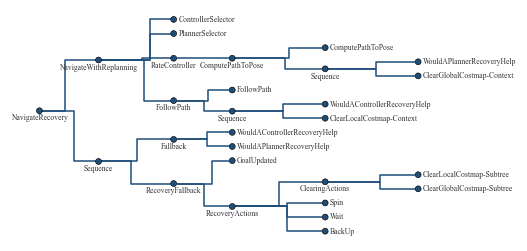

In [19]:
# ---- Figure: nav_to_pose behaviour tree, nodes blue, each node labelled with its name ----
# Left-to-right layout (root at left): each tree level is a column, spaced by the widest label
# in that level so a label never collides with the next column. Two-column width because the
# long recovery-node names need the space. Edges are routed orthogonally in the corridor
# between columns; non-leaf labels are centred BELOW their node (never crossing the outgoing
# edge lines), leaf labels go to the right (leaves have no outgoing edges).  The vertical
# elbow segment for each edge is placed per-edge to sit exactly between the right edge of
# the parent's label and the left edge of the child's label.
from collections import defaultdict
from matplotlib.text import TextPath

FS = 5.0       # label font size (pt)
XM = 12.0      # vertical node spacing within a level (pt)
DIAM = 5.0     # node circle diameter (pt)
GAP = 8.0      # horizontal gap after a level's widest label (pt)
LBL_GAP = 1.5  # vertical gap between a non-leaf node and its label below (pt)
MARGIN = 1.5   # horizontal clearance each side of the elbow vertical (pt)

t = parse_bt_xml(TREES["nav_to_pose_secorolab"]["xml_path"])
names, parents = t["names"], t["parents"]
children, roots = defaultdict(list), []
for i, p in parents.items():
    (roots if p is None else children[p]).append(i)

wlab = {nm: TextPath((0, 0), nm, size=FS).get_extents().width for nm in set(names)}
hlab = TextPath((0, 0), "Xgy", size=FS).get_extents().height

depth = {}
def _depth(i, d):
    depth[i] = d
    for j in children[i]:
        _depth(j, d + 1)
for r in roots:
    _depth(r, 0)
levels = defaultdict(list)
for i in range(len(names)):
    levels[depth[i]].append(i)

# vertical positions: leaves stack top-to-bottom, parents centred over their children
pos_y, ycur = {}, [0.0]
def place_y(i):
    if children[i]:
        for c in children[i]:
            place_y(c)
        ys = [pos_y[c] for c in children[i]]
        pos_y[i] = (min(ys) + max(ys)) / 2.0
    else:
        pos_y[i] = ycur[0]
        ycur[0] -= XM
for r in roots:
    place_y(r)

# horizontal offset per level: widest label + circle + gap
xpos, xcur = {}, 0.0
for d in sorted(levels):
    xpos[d] = xcur
    xcur += max(wlab[names[i]] for i in levels[d]) + DIAM + GAP

# ---- label geometry helpers ----
def label_bbox(i):
    """Return (left, right, bottom, top) of the label rectangle for node i."""
    x, y = xpos[depth[i]], pos_y[i]
    if children[i]:
        yc = y - DIAM/2 - LBL_GAP - hlab/2
        return x - wlab[names[i]]/2, x + wlab[names[i]]/2, yc - hlab/2, yc + hlab/2
    return x + DIAM/2 + 1.5, x + DIAM/2 + 1.5 + wlab[names[i]], y - hlab/2, y + hlab/2

def label_right(i):
    """Rightmost x-extent of the label (and/or node) for edge routing."""
    x = xpos[depth[i]]
    if children[i]:          # label centred below
        return x + wlab[names[i]] / 2
    return x + DIAM/2 + 1.5 + wlab[names[i]]   # label right-aligned

def label_left(i):
    """Leftmost x-extent of the label (and/or node) for edge routing."""
    x = xpos[depth[i]]
    if children[i]:          # label centred below
        return x - wlab[names[i]] / 2
    return x - DIAM/2        # leaf: no left label, just the node circle

# ---- elbow vertical x per edge: midpoint between parent label right and child label left ----
elbow_x = {}
for i, p in parents.items():
    if p is not None:
        pr = label_right(p) + MARGIN
        cl = label_left(i) - MARGIN
        elbow_x[i] = (pr + cl) / 2.0

# figure extent from the artists themselves
all_bboxes = [label_bbox(i) for i in range(len(names))]
xs_l = min(min(xpos[depth[i]] - DIAM/2 for i in range(len(names))),
           min(b[0] for b in all_bboxes))
xs_r = max(max(xpos[depth[i]] + DIAM/2 for i in range(len(names))),
           max(b[1] for b in all_bboxes))
ys_t = max(pos_y.values()) + DIAM/2
ys_b = min(min(pos_y[i] - DIAM/2 for i in range(len(names)) if not children[i]),
           min(b[2] for b in all_bboxes))

PAD = 5.0
figw = (xs_r - xs_l + 2 * PAD) / 72.0
figh = (ys_t - ys_b + 2 * PAD) / 72.0

fig, ax = plt.subplots(figsize=(min(figw, TWO_COLUMNS), figh))
for i, p in parents.items():
    if p is not None:
        x0 = xpos[depth[p]] + DIAM/2          # start at parent right rim
        x1 = xpos[depth[i]] - DIAM/2          # end   at child  left  rim
        xm = elbow_x[i]
        y0, y1 = pos_y[p], pos_y[i]
        ax.plot([x0, xm, xm, x1], [y0, y0, y1, y1],
                color="#1f4e79", lw=1.0, solid_capstyle="butt", zorder=1)
for i in range(len(names)):
    x, y = xpos[depth[i]], pos_y[i]
    ax.add_patch(plt.Circle((x, y), DIAM/2, fc="#1f4e79", ec="black", lw=0.4, zorder=2))
    if children[i]:
        ax.text(x, y - DIAM/2 - LBL_GAP - hlab/2, names[i], fontsize=FS,
                ha="center", va="center", zorder=3)
    else:
        ax.text(x + DIAM/2 + 1.5, y, names[i], fontsize=FS, ha="left", va="center", zorder=3)
ax.set_xlim(xs_l - PAD, xs_r + PAD)
ax.set_ylim(ys_b - PAD, ys_t + PAD)
ax.set_aspect("equal")
ax.set_axis_off()

fout = DATA_ROOT / "fig3_btree_nav_to_pose.png"
fig.savefig(fout, dpi=300, bbox_inches="tight")
print(f"saved: {fout}  ({len(names)} nodes, left-to-right layout)")
plt.show()


## Reading Figure 3

Both panels draw the identical 22-node behaviour tree, so the comparison is direct. In
the stock Nav2 system-test suite only the navigation spine (NavigateRecovery,
NavigateWithReplanning, ControllerSelector, PlannerSelector, RateController,
ComputePathToPose, FollowPath) is ever activated; the entire recovery payload --- the
Clear*Costmap chain, Spin, Wait, BackUp and the WouldA*RecoveryHelp guards --- stays
red, because none of the 70 runs triggered a single recovery node. In the QD campaign
every declared node is reached, so all 22 turn green. The border colour distinguishes
node type: blue = control flow, purple = recovery-wrapped nodes, brown = recovery
actions (Spin, Wait, BackUp), pink = the Clear*Costmap chain, cyan = conditions.
Figure 3 makes the reachability gap between the framework's own tests and the
search-generated scenarios visible node by node.


## Paper Figure 1 (fig:nav2-sys-tests): Nav2 system-test heat map

Simple heat map: 15 test campaigns (the official suite minus `drive-heading` and
`wrong-init`) on the horizontal axis, the 25 behaviours on the vertical axis (rarest
on top). Cell colour = the number of that campaign's runs in which the behaviour was
triggered. Tree-ticking campaigns are counted from their per-run `nav2_behaviors.csv`;
the behaviour-server and error-code tests (`spin`, `wait`, `error-codes`) call behaviour
servers directly and never tick the tree, so their in-tree behaviours (`Spin`, `Wait`,
`FollowPath`, `ComputePathToPose`, `ComputePathThroughPoses`) count all of the campaign's
runs. The 13 behaviours no stock test exercises stay white at the top.

saved: /home/sam/Downloads/ICRA analysis/ICRA_paper_overleaf/fig1_nav2_systests.png  (15 tests x 25 behaviours, suite union 12/25)


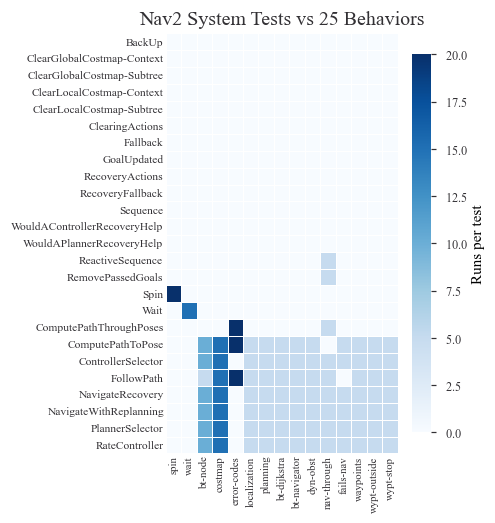

In [20]:
# ---- Paper Figure 1: seaborn heatmap, 15 tests x 25 behaviours, cell = # runs triggering ----
import csv

EXCLUDED = {"test-drive-on-heading-behavior-2026-09-06-15242717",
            "test-bt-navigator-with-wrong-init-pose-2026-09-06-10143726"}
# behaviours reached only through *direct* behaviour-server calls
DIRECT_MAP = {
    "test-spin-behavior-2026-09-06-15094116":             {"Spin"},
    "test-wait-behavior-2026-09-06-15015548":             {"Wait"},
    "test-error-codes-2026-09-06-14382214": {"FollowPath", "ComputePathToPose",
                                             "ComputePathThroughPoses"},
}

def nav2_test_matrix():
    """15 campaigns x 25 behaviours; cell = # runs of that campaign triggering the behaviour."""
    to_pose_xml = SYSTEM_ROOT / "system" / "test-bt-navigator-2026-09-06-10075304" \
                  / "_config" / "files" / "navigate_to_pose_w_replanning_and_recovery.xml"
    thru_xml = SYSTEM_ROOT / "system" / "test-nav-through-poses-2026-09-06-10461058" \
               / "_config" / "files" / "navigate_through_poses_w_replanning_and_recovery.xml"
    universe = set(parse_bt_xml(to_pose_xml)["names"]) | set(parse_bt_xml(thru_xml)["names"])
    camps = sorted(p.parent for p in SYSTEM_ROOT.rglob("campaign.db")
                   if p.parent.name not in EXCLUDED)
    counts = {}
    for c in camps:
        cnt = {b: 0 for b in universe}
        if c.name in DIRECT_MAP:                          # direct behaviour-server calls
            n_runs = sum(1 for p in c.rglob("behaviors.jsonl") if p.parent.name.isdigit())
            for b in DIRECT_MAP[c.name]:
                cnt[b] = n_runs
        else:                                            # per-run tree tick, nav2_behaviors.csv
            for csvp in c.rglob("nav2_behaviors.csv"):
                if not csvp.parent.name.isdigit():
                    continue
                run_hit = set()
                with open(csvp) as f:
                    for row in csv.DictReader(f):
                        st = row.get("status_name", "")
                        if st not in ("INVALID", "IDLE", ""):
                            run_hit.add(row["behavior_name"])
                for b in (run_hit & universe):
                    cnt[b] += 1
        counts[c.name] = cnt
    return universe, [c.name for c in camps], counts

TEST_LABELS = {
    "test-spin-behavior-2026-09-06-15094116": "spin",
    "test-wait-behavior-2026-09-06-15015548": "wait",
    "test-behavior-tree-node-2026-09-06-16170101": "bt-node",
    "costmap-filter-2026-09-06-13464724": "costmap",
    "test-error-codes-2026-09-06-14382214": "error-codes",
    "test-localization-2026-09-06-16464638": "localization",
    "planning-2026-09-06-18165849": "planning",
    "test-bt-navigator-with-dijkstra-2026-09-06-10102725": "bt-dijkstra",
    "test-bt-navigator-2026-09-06-10075304": "bt-navigator",
    "test-dynamic-obstacle-2026-09-06-10363206": "dyn-obst",
    "test-nav-through-poses-2026-09-06-10461058": "nav-through",
    "test-failure-navigator-2026-09-06-14285835": "fails-nav",
    "test-waypoint-follower-2026-09-06-14105254": "waypoints",
    "test-waypoint-follower-outside-map-2026-09-06-14134612": "wypt-outside",
    "test-waypoint-follower-stop-on-failure-2026-09-06-14223244": "wypt-stop",
}
CAT_ORDER = ["spin", "wait", "bt-node", "costmap", "error-codes", "localization",
             "planning", "bt-dijkstra", "bt-navigator", "dyn-obst", "nav-through",
             "fails-nav", "waypoints", "wypt-outside", "wypt-stop"]

universe, test_camps, n_run_trigger = nav2_test_matrix()
n_tests = {b: sum(1 for c in test_camps if n_run_trigger[c][b] > 0) for b in universe}
order = sorted(universe, key=lambda b: (n_tests[b], b))              # rarest on top
abbr_to_camp = {v: k for k, v in TEST_LABELS.items()}
camp_order = [abbr_to_camp[a] for a in CAT_ORDER]
M = pd.DataFrame({a: [n_run_trigger[c][b] for b in order] for c, a in zip(camp_order, CAT_ORDER)},
                 index=order)

# ---- seaborn heatmap with cell borders and a colorbar ----
fig, ax = plt.subplots(figsize=(SINGLE_COLUMN, 4.96))
sns.heatmap(M, ax=ax, cmap="Blues", cbar=True, linewidths=0.4, linecolor="white",
            cbar_kws={"shrink": 0.9},
            xticklabels=True, yticklabels=True)
ax.set_title("Nav2 System Tests vs 25 Behaviors", fontsize=13)
ax.tick_params(length=0, pad=1.5)
ax.set_xticklabels(ax.get_xticklabels(), rotation=90, fontsize=7, ha="center")
ax.set_yticklabels(ax.get_yticklabels(), fontsize=7.5)
cb = ax.collections[0].colorbar
cb.ax.tick_params(labelsize=8)
cb.set_label("Runs per test", fontsize=10)

fout = DATA_ROOT / "ICRA_paper_overleaf" / "fig1_nav2_systests.png"
fig.savefig(fout, dpi=300, bbox_inches="tight")
print(f"saved: {fout}  ({M.shape[1]} tests x {len(order)} behaviours, "
      f"suite union {sum(1 for b in universe if n_tests[b]>0)}/{len(universe)})")
plt.show()

## Reading the figure

This is one representative campaign (`nav_to_pose`, offices) of the six executed;
the other five show the same shape. The **offices** campaigns reach a best-so-far of 1.0:
at least one configuration activates every declared node of the tree in all five of its runs
(here by batch 12). From the first batch the search already clears the **40.9%** coverage of the stock Nav2
system-test suite on the to-pose tree, 9/22 (dotted line). The band's bottom edge stays at 7/22 = 0.318
--- the clean-navigation floor every run reaches --- never down to 0. The best-so-far curve
saturates well before the 15-batch budget is exhausted: later batches refine behavioural
diversity in the archive (its measure space) rather than coverage.


## Map figure (paper fig:placeholder): stock-suite and optimization paths

Two panels. Top: the 15 nav2 system-test campaigns' best runs (by per-run coverage) on the
hexagon map. Bottom: the cumulative-best runs of the nav_to_pose (offices) optimization
campaign on the secorolab map, labelled with the 1-indexed batch in which each new
coverage record was set. Coverage = distinct non-IDLE behaviours in the run's
`nav2_behaviors.csv` over the 25-node universe; colours on a shared Viridis scale;
`o` = start pose, `*` = goal pose.

drew: 15 stock tests, 5 record paths
  batch 1: cov=0.80 traveled=2 planned=420 progress=419
  batch 2: cov=0.80 traveled=2 planned=411 progress=253
  batch 3: cov=0.80 traveled=2 planned=424 progress=250
  batch 5: cov=0.84 traveled=2 planned=333 progress=226
  batch 12: cov=0.88 traveled=2 planned=296 progress=169


saved: /home/sam/Downloads/ICRA analysis/ICRA_paper_overleaf/fig_maps_paths.png


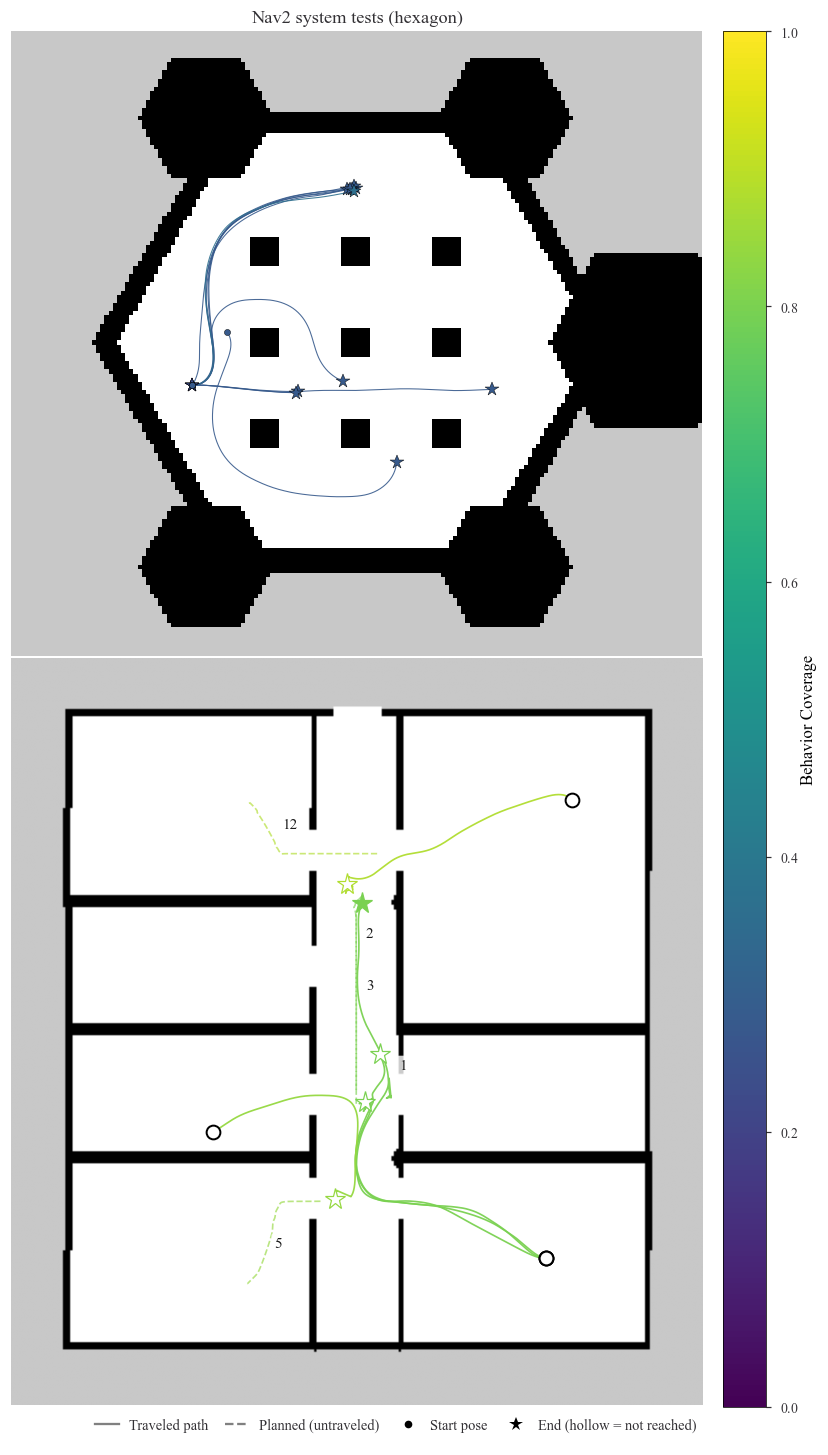

In [21]:
# ---- Paper map figure (fig:placeholder): 15 tests on the hexagon + nav_to_pose offices records ----
import csv, sqlite3
from PIL import Image
from rosbags.highlevel import AnyReader
import matplotlib.colors as mcolors

# ---- map loading ----
def load_map(pgm_path, origin, res):
    img = np.asarray(Image.open(pgm_path), dtype=np.float32)
    rows, cols = img.shape
    def w2p(x, y):
        return (np.asarray(x) - origin[0]) / res, \
               (origin[1] + rows * res - np.asarray(y)) / res
    return img, w2p

HEX, hex_w2p = load_map(
    SYSTEM_ROOT / "system" / "test-bt-navigator-2026-09-06-10075304"
    / "_config" / "environments" / "hexagon" / "maps" / "hexagon.pgm",
    (-4.182938, -3.79), 0.05)
SECO, seco_w2p = load_map(
    OPT / "qd-nav-to-pose-secorolab-2026-09-08-01140915.incomplete"
    / "qd-nav-to-pose-secorolab-2026-09-08-01140915"
    / "_config" / "environments" / "secorolab" / "maps" / "secorolab.pgm",
    (-7.2, -7.75), 0.05)

# ---- behaviour universe + helpers ----
to_pose_xml = SYSTEM_ROOT / "system" / "test-bt-navigator-2026-09-06-10075304" \
    / "_config" / "files" / "navigate_to_pose_w_replanning_and_recovery.xml"
thru_xml = SYSTEM_ROOT / "system" / "test-nav-through-poses-2026-09-06-10461058" \
    / "_config" / "files" / "navigate_through_poses_w_replanning_and_recovery.xml"
UNIVERSE = set(parse_bt_xml(to_pose_xml)["names"]) | set(parse_bt_xml(thru_xml)["names"])

def run_coverage(csvp):
    reached = set()
    with open(csvp) as f:
        for row in csv.DictReader(f):
            if row.get("status_name", "") not in ("INVALID", "IDLE", ""):
                reached.add(row["behavior_name"])
    return len(reached & UNIVERSE) / len(UNIVERSE)

def sim_path(csv_path):
    xs, ys = [], []
    with open(csv_path) as f:
        for row in csv.DictReader(f):
            if row.get("frame") != "base_link":
                continue
            xs.append(float(row["position.x"])); ys.append(float(row["position.y"]))
    return np.array([xs, ys]) if len(xs) >= 2 else None

def read_plan(bag_dir, run_idx):
    """Return first /plan poses as (2, N) array or None."""
    bag = Path(bag_dir) / str(run_idx) / "rosbag2"
    if not (bag / "metadata.yaml").exists():
        return None
    try:
        with AnyReader([bag]) as rdr:
            for c in rdr.connections:
                if c.topic == "/plan":
                    for conn, ts, raw in rdr.messages(connections=[c]):
                        msg = rdr.deserialize(raw, conn.msgtype)
                        if msg.poses:
                            return np.array([[p.pose.position.x for p in msg.poses],
                                             [p.pose.position.y for p in msg.poses]])
                    break
    except Exception:
        pass
    return None

def plan_progress(traveled, planned, thresh=0.3):
    """Index of last planned point the robot got near."""
    d = np.linalg.norm(traveled.T[:, None, :] - planned.T[None, :, :], axis=2)  # (Nt, Np)
    reached = np.where(d.min(axis=0) <= thresh)[0]
    return int(reached[-1]) if len(reached) else 0

TELEPORT_M = 1.0   # threshold to detect the spawn-idle → true-start teleport jump
def trim_teleport(pth):
    """Strip leading spawn-idle + teleport prefix; return trimmed path array."""
    if pth is None or pth.shape[1] < 2:
        return pth
    d = np.linalg.norm(np.diff(pth, axis=1), axis=0)
    jumps = np.where(d > TELEPORT_M)[0]
    if len(jumps) == 0:
        return pth
    return pth[:, int(jumps[0]) + 1:]

# ---- Panel A: 15 stock tests, best run per test ----
DIRECT_MAP = {
    "test-spin-behavior-2026-09-06-15094116":             {"Spin"},
    "test-wait-behavior-2026-09-06-15015548":             {"Wait"},
    "test-error-codes-2026-09-06-14382214": {"FollowPath", "ComputePathToPose",
                                             "ComputePathThroughPoses"},
}
CAMP_ABBR = {
    "test-spin-behavior-2026-09-06-15094116": "spin",
    "test-wait-behavior-2026-09-06-15015548": "wait",
    "test-behavior-tree-node-2026-09-06-16170101": "bt-node",
    "costmap-filter-2026-09-06-13464724": "costmap",
    "test-error-codes-2026-09-06-14382214": "error-codes",
    "test-localization-2026-09-06-16464638": "localization",
    "planning-2026-09-06-18165849": "planning",
    "test-bt-navigator-with-dijkstra-2026-09-06-10102725": "bt-dijkstra",
    "test-bt-navigator-2026-09-06-10075304": "bt-navigator",
    "test-dynamic-obstacle-2026-09-06-10363206": "dyn-obst",
    "test-nav-through-poses-2026-09-06-10461058": "nav-through",
    "test-failure-navigator-2026-09-06-14285835": "fails-nav",
    "test-waypoint-follower-2026-09-06-14105254": "waypoints",
    "test-waypoint-follower-outside-map-2026-09-06-14134612": "wypt-outside",
    "test-waypoint-follower-stop-on-failure-2026-09-06-14223244": "wypt-stop",
}
EXCLUDED = {"test-drive-on-heading-behavior-2026-09-06-15242717",
            "test-bt-navigator-with-wrong-init-pose-2026-09-06-10143726"}

def best_run(camp_dir):
    if camp_dir.name in DIRECT_MAP:
        cov = len(DIRECT_MAP[camp_dir.name] & UNIVERSE) / len(UNIVERSE)
        sp = sorted(p for p in camp_dir.rglob("sim_poses.csv") if p.parent.name.isdigit())
        if not sp: return None
        pth = sim_path(sp[0])
        return (cov, pth, sp[0].parent) if pth is not None else None
    best = None
    for csvp in camp_dir.rglob("nav2_behaviors.csv"):
        if not csvp.parent.name.isdigit(): continue
        cov = run_coverage(csvp)
        if best is None or cov > best[0]:
            best = (cov, csvp.parent)
    if best is None: return None
    cov, rundir = best
    sp = rundir / "sim_poses.csv"
    pth = sim_path(sp) if sp.exists() else None
    return (cov, pth, rundir) if pth is not None else None

panelA = []
for db in sorted(SYSTEM_ROOT.rglob("campaign.db")):
    c = db.parent
    if c.name in EXCLUDED or c.name not in CAMP_ABBR: continue
    r = best_run(c)
    if r:
        panelA.append((CAMP_ABBR[c.name], r[0], r[1]))

# strip leading spawn-idle + teleport from all system-test paths
panelA = [(abbr, cov, trim_teleport(pth)) for abbr, cov, pth in panelA]

# ---- Panel B: nav_to_pose_secorolab cumulative-best records ----
camp = OPT / "qd-nav-to-pose-secorolab-2026-09-08-01140915.incomplete" \
       / "qd-nav-to-pose-secorolab-2026-09-08-01140915"
conn = sqlite3.connect(camp / "campaign.db")
rows = conn.execute(
    "SELECT b.idx, u.id, u.objective, u.result_dir FROM unit u "
    "JOIN batch b ON u.batch_id=b.id WHERE u.objective IS NOT NULL "
    "ORDER BY b.idx, u.id").fetchall()
conn.close()
by_batch = {}
for b, uid, obj, rd in rows:
    by_batch.setdefault(b, []).append((uid, obj, rd))
records, running = [], -1.0
for b in sorted(by_batch):
    uid, obj, rd = max(by_batch[b], key=lambda t: t[1])
    if obj > running:
        records.append((b, uid, rd))
        running = obj

panelB = []   # (1-indexed batch label, coverage, traveled, planned, run_dir)
for b, uid, rd in records:
    best = None
    for csvp in (camp / rd).rglob("nav2_behaviors.csv"):
        if not csvp.parent.name.isdigit(): continue
        cov = run_coverage(csvp)
        if best is None or cov > best[0]:
            best = (cov, csvp.parent)
    if best is None: continue
    cov, rundir = best
    sp = rundir / "sim_poses.csv"
    traveled = sim_path(sp) if sp.exists() else None
    planned  = read_plan(camp / rd, rundir.name)   # rundir.name is 0..4
    if traveled is not None:
        panelB.append((b + 1, cov, traveled, planned, rundir))

print(f"drew: {len(panelA)} stock tests, {len(panelB)} record paths")
for label, cov, trav, pln, _ in panelB:
    prog = plan_progress(trav, pln) if pln is not None else 0
    print(f"  batch {label}: cov={cov:.2f} traveled={len(trav)} planned={None if pln is None else pln.shape[1]} progress={prog}")

# strip leading spawn-idle + teleport from all record paths
panelB = [(l, c, trim_teleport(t), pl, r) for l, c, t, pl, r in panelB]

# ---- render (stacked, aspect-matched, no white space) ----
norm = mcolors.Normalize(vmin=0.0, vmax=1.0)
cmap = plt.get_cmap("viridis")
HEX_R  = HEX.shape[0] / HEX.shape[1]
SECO_R = SECO.shape[0] / SECO.shape[1]
SCALE = TWO_COLUMNS / 5.6                    # scale the 5.6in layout to two-column width
PANEL_W = 5.04 * SCALE                       # panel width (inches)
XR, CBX, CBW = 0.90, 0.925, 0.055            # right edge, colorbar box (figure fractions)
RSUM = HEX_R + SECO_R
FIG_H = PANEL_W * RSUM                       # panel-only height (inches)
LEG_H = 0.34                                 # explicit legend band at the bottom (inches)
H_TOT = FIG_H + LEG_H
fig = plt.figure(figsize=(TWO_COLUMNS, H_TOT))
L = LEG_H / H_TOT                            # legend band (figure fraction)
f = FIG_H / H_TOT                            # panels occupy the top fraction
ax2 = fig.add_axes([0.0, L, XR, f * SECO_R / RSUM])
ax1 = fig.add_axes([0.0, L + f * SECO_R / RSUM, XR, f * HEX_R / RSUM])  # touches ax2
cax = fig.add_axes([CBX, L, CBW, f])         # colorbar aligned with the panels

for ax, img, w2p, title in [(ax1, HEX, hex_w2p,  "Nav2 system tests (hexagon)"),
                            (ax2, SECO, seco_w2p, "Nav-to-pose optimization (offices)")]:
    ax.imshow(img, cmap="gray", origin="upper", aspect="auto")
    rows, cols = img.shape
    ax.set_xlim(0, cols); ax.set_ylim(rows, 0)
    ax.set_axis_off()
    ax.set_title(title, fontsize=12)

# --- Panel A: stock tests (solid lines only) ---
for abbr, cov, pth in panelA:
    px, py = hex_w2p(pth[0], pth[1])
    c = cmap(norm(cov))
    ax1.plot(px, py, lw=0.7, color=c, alpha=0.9, zorder=3)
    ax1.plot(px[0], py[0], "o", ms=4, mfc=c, mec="k", mew=0.3, zorder=4)
    ax1.plot(px[-1], py[-1], "*", ms=9, mfc=c, mec="k", mew=0.3, zorder=4)

# --- Panel B: optimization records (solid = travelled, dotted = plan not travelled) ---
meta = []
for label, cov, traveled, planned, rundir in panelB:
    px, py = seco_w2p(traveled[0], traveled[1])
    c = cmap(norm(cov))
    ax2.plot(px, py, lw=1.1, color=c, alpha=0.95, zorder=3)
    ax2.plot(px[0], py[0], "o", ms=9, mfc="w", mec="k", mew=1.3, zorder=7)
    prog = plan_progress(traveled, planned) if planned is not None else None
    if planned is not None and prog < planned.shape[1] - 2:
        ppx, ppy = seco_w2p(planned[0][prog:], planned[1][prog:])
        ax2.plot(ppx, ppy, "--", lw=1.1, color=c, alpha=0.65, zorder=3)
    reached = (planned is None) or (prog >= planned.shape[1] - 3)
    sx, sy = seco_w2p(traveled[0][-1], traveled[1][-1])   # stopping point (pixels)
    ax2.plot(sx, sy, "*", ms=14, mfc=c if reached else "w", mec=c, mew=0.8, zorder=6)
    meta.append((label, cov, traveled, planned, reached, float(sx), float(sy)))


# batch labels placed along each line at well-separated anchors (no overlaps)
cand_by_label = {}
for label, cov, traveled, planned, reached, sx, sy in meta:
    cands = []
    n = traveled.shape[1]
    cands.append(("trav-half", tuple(map(float, seco_w2p(traveled[0][n // 2], traveled[1][n // 2])))))
    cands.append(("trav-75",  tuple(map(float, seco_w2p(traveled[0][int(n * 0.75)], traveled[1][int(n * 0.75)])))))
    if planned is not None and not reached:
        seg = planned[:, plan_progress(traveled, planned):]
        m = seg.shape[1] // 2
        cands.append(("dot-half", tuple(map(float, seco_w2p(seg[0][m], seg[1][m])))))
        cands.append(("dot-75",   tuple(map(float, seco_w2p(seg[0][int(seg.shape[1] * 0.75)], seg[1][int(seg.shape[1] * 0.75)])))))
    cand_by_label[label] = cands

anchors = {}
taken = []
for label, cov, traveled, planned, reached, sx, sy in meta:
    best = None
    for name, pt in cand_by_label[label]:
        stx, sty = seco_w2p(traveled[0][0], traveled[1][0])   # this record's own start marker
        if np.hypot(pt[0] - stx, pt[1] - sty) < 20:      # keep clear of start marker
            continue
        if np.hypot(pt[0] - sx, pt[1] - sy) < 20:                    # keep clear of own end marker
            continue
        md = min([np.hypot(pt[0] - cx, pt[1] - cy) for cx, cy in taken], default=1e9) if taken else 1e9
        if best is None or md > best[2]:
            best = (name, pt, md)
    name, pt, md = best
    taken.append(pt)
    anchors[label] = (name, pt, md)

for label, cov, traveled, planned, reached, sx, sy in meta:
    name, (ax_, ay_), md = anchors[label]
    ax2.annotate(str(label), xy=(ax_, ay_), xytext=(ax_ + 4, ay_ - 4), fontsize=10, color="0.1",
                 bbox=dict(boxstyle="round,pad=0.18", fc="white", alpha=0.8, ec="none"), zorder=6)

# ---- shared colorbar ----
sm = plt.cm.ScalarMappable(norm=norm, cmap=cmap)
sm.set_array([])
cbar = fig.colorbar(sm, cax=cax)
cbar.set_label("Behavior Coverage", fontsize=11)
cbar.ax.tick_params(labelsize=9)

# ---- legend ----
legend_lines = [
    plt.Line2D([0],[0], color="gray", lw=1.5, label="Traveled path"),
    plt.Line2D([0],[0], color="gray", lw=1.5, ls="--", label="Planned (untraveled)"),
    plt.Line2D([0],[0], marker="o", color="w", markerfacecolor="k", ms=5,  label="Start pose"),
    plt.Line2D([0],[0], marker="*", color="w", markerfacecolor="k", ms=9,  label="End (hollow = not reached)"),
]
legax = fig.add_axes([0.0, 0.0, 1.0, L])
legax.set_axis_off()
legax.legend(handles=legend_lines, loc="center", ncol=4, fontsize=9.5, frameon=False,
             handlelength=1.6, columnspacing=1.2, handletextpad=0.7, borderaxespad=0)

fout = DATA_ROOT / "ICRA_paper_overleaf" / "fig_maps_paths.png"
fig.savefig(fout, dpi=300, bbox_inches="tight", pad_inches=0)
print(f"saved: {fout}")
plt.show()

drew: 15 stock tests, 2 record paths
  batch 1: cov=0.88 traveled=2 planned=145 progress=109
  batch 5: cov=0.88 traveled=2 planned=158 progress=126


saved: /home/sam/Downloads/ICRA analysis/ICRA_paper_overleaf/fig_maps_paths_single.png


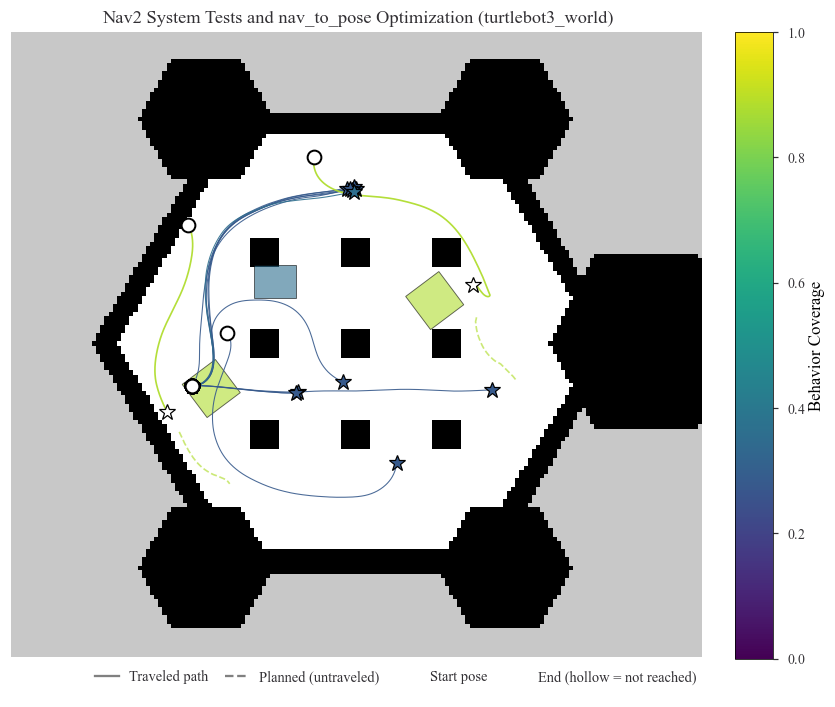

In [22]:
# ---- Variant: 15 tests on the hexagon + nav_to_pose HEXAGON optimization records ----
import csv, sqlite3
from PIL import Image
from rosbags.highlevel import AnyReader
import matplotlib.colors as mcolors

# ---- map loading ----
def load_map(pgm_path, origin, res):
    img = np.asarray(Image.open(pgm_path), dtype=np.float32)
    rows, cols = img.shape
    def w2p(x, y):
        return (np.asarray(x) - origin[0]) / res, \
               (origin[1] + rows * res - np.asarray(y)) / res
    return img, w2p

HEX, hex_w2p = load_map(
    SYSTEM_ROOT / "system" / "test-bt-navigator-2026-09-06-10075304"
    / "_config" / "environments" / "hexagon" / "maps" / "hexagon.pgm",
    (-4.182938, -3.79), 0.05)
TB3, tb3_w2p = load_map(
    OPT / "qd-nav-to-pose-hexagon-2026-09-08-01141390.incomplete"
    / "qd-nav-to-pose-hexagon-2026-09-08-01141390"
    / "_config" / "environments" / "tb3_world" / "maps" / "tb3_world.pgm",
    (-4.2995550552369775, -4.398499976705619), 0.05)

# ---- behaviour universe + helpers ----
to_pose_xml = SYSTEM_ROOT / "system" / "test-bt-navigator-2026-09-06-10075304" \
    / "_config" / "files" / "navigate_to_pose_w_replanning_and_recovery.xml"
thru_xml = SYSTEM_ROOT / "system" / "test-nav-through-poses-2026-09-06-10461058" \
    / "_config" / "files" / "navigate_through_poses_w_replanning_and_recovery.xml"
UNIVERSE = set(parse_bt_xml(to_pose_xml)["names"]) | set(parse_bt_xml(thru_xml)["names"])

def run_coverage(csvp):
    reached = set()
    with open(csvp) as f:
        for row in csv.DictReader(f):
            if row.get("status_name", "") not in ("INVALID", "IDLE", ""):
                reached.add(row["behavior_name"])
    return len(reached & UNIVERSE) / len(UNIVERSE)

def sim_path(csv_path):
    xs, ys = [], []
    with open(csv_path) as f:
        for row in csv.DictReader(f):
            if row.get("frame") != "base_link":
                continue
            xs.append(float(row["position.x"])); ys.append(float(row["position.y"]))
    return np.array([xs, ys]) if len(xs) >= 2 else None

def read_plan(bag_dir, run_idx):
    """Return first /plan poses as (2, N) array or None."""
    bag = Path(bag_dir) / str(run_idx) / "rosbag2"
    if not (bag / "metadata.yaml").exists():
        return None
    try:
        with AnyReader([bag]) as rdr:
            for c in rdr.connections:
                if c.topic == "/plan":
                    for conn, ts, raw in rdr.messages(connections=[c]):
                        msg = rdr.deserialize(raw, conn.msgtype)
                        if msg.poses:
                            return np.array([[p.pose.position.x for p in msg.poses],
                                             [p.pose.position.y for p in msg.poses]])
                    break
    except Exception:
        pass
    return None

def plan_progress(traveled, planned, thresh=0.3):
    """Index of last planned point the robot got near."""
    d = np.linalg.norm(traveled.T[:, None, :] - planned.T[None, :, :], axis=2)  # (Nt, Np)
    reached = np.where(d.min(axis=0) <= thresh)[0]
    return int(reached[-1]) if len(reached) else 0

TELEPORT_M = 1.0   # threshold to detect the spawn-idle → true-start teleport jump
def trim_teleport(pth):
    """Strip leading spawn-idle + teleport prefix; return trimmed path array."""
    if pth is None or pth.shape[1] < 2:
        return pth
    d = np.linalg.norm(np.diff(pth, axis=1), axis=0)
    jumps = np.where(d > TELEPORT_M)[0]
    if len(jumps) == 0:
        return pth
    return pth[:, int(jumps[0]) + 1:]

# ---- Panel A: 15 stock tests, best run per test ----
DIRECT_MAP = {
    "test-spin-behavior-2026-09-06-15094116":             {"Spin"},
    "test-wait-behavior-2026-09-06-15015548":             {"Wait"},
    "test-error-codes-2026-09-06-14382214": {"FollowPath", "ComputePathToPose",
                                             "ComputePathThroughPoses"},
}
CAMP_ABBR = {
    "test-spin-behavior-2026-09-06-15094116": "spin",
    "test-wait-behavior-2026-09-06-15015548": "wait",
    "test-behavior-tree-node-2026-09-06-16170101": "bt-node",
    "costmap-filter-2026-09-06-13464724": "costmap",
    "test-error-codes-2026-09-06-14382214": "error-codes",
    "test-localization-2026-09-06-16464638": "localization",
    "planning-2026-09-06-18165849": "planning",
    "test-bt-navigator-with-dijkstra-2026-09-06-10102725": "bt-dijkstra",
    "test-bt-navigator-2026-09-06-10075304": "bt-navigator",
    "test-dynamic-obstacle-2026-09-06-10363206": "dyn-obst",
    "test-nav-through-poses-2026-09-06-10461058": "nav-through",
    "test-failure-navigator-2026-09-06-14285835": "fails-nav",
    "test-waypoint-follower-2026-09-06-14105254": "waypoints",
    "test-waypoint-follower-outside-map-2026-09-06-14134612": "wypt-outside",
    "test-waypoint-follower-stop-on-failure-2026-09-06-14223244": "wypt-stop",
}
EXCLUDED = {"test-drive-on-heading-behavior-2026-09-06-15242717",
            "test-bt-navigator-with-wrong-init-pose-2026-09-06-10143726"}

def best_run(camp_dir):
    if camp_dir.name in DIRECT_MAP:
        cov = len(DIRECT_MAP[camp_dir.name] & UNIVERSE) / len(UNIVERSE)
        sp = sorted(p for p in camp_dir.rglob("sim_poses.csv") if p.parent.name.isdigit())
        if not sp: return None
        pth = sim_path(sp[0])
        return (cov, pth, sp[0].parent) if pth is not None else None
    best = None
    for csvp in camp_dir.rglob("nav2_behaviors.csv"):
        if not csvp.parent.name.isdigit(): continue
        cov = run_coverage(csvp)
        if best is None or cov > best[0]:
            best = (cov, csvp.parent)
    if best is None: return None
    cov, rundir = best
    sp = rundir / "sim_poses.csv"
    pth = sim_path(sp) if sp.exists() else None
    return (cov, pth, rundir) if pth is not None else None

panelA = []
sys_obs = {}   # abbr -> (cov, static-obstacle instances) for tests that place boxes
import yaml as _yaml
for db in sorted(SYSTEM_ROOT.rglob("campaign.db")):
    c = db.parent
    if c.name in EXCLUDED or c.name not in CAMP_ABBR: continue
    r = best_run(c)
    if r:
        panelA.append((CAMP_ABBR[c.name], r[0], r[1]))
        for cfg in c.glob("*/_config/sim.config"):
            sc = _yaml.safe_load(cfg.read_text())
            insts = sc.get("overrides", {}).get("components", {}).get("static_obstacles", {}).get("instances", [])
            if insts:
                sys_obs[CAMP_ABBR[c.name]] = (r[0], insts)

# strip leading spawn-idle + teleport from all system-test paths
panelA = [(abbr, cov, trim_teleport(pth)) for abbr, cov, pth in panelA]

# ---- Panel B: nav_to_pose_hexagon cumulative-best records ----
camp = OPT / "qd-nav-to-pose-hexagon-2026-09-08-01141390.incomplete" \
       / "qd-nav-to-pose-hexagon-2026-09-08-01141390"
conn = sqlite3.connect(camp / "campaign.db")
rows = conn.execute(
    "SELECT b.idx, u.id, u.objective, u.result_dir FROM unit u "
    "JOIN batch b ON u.batch_id=b.id WHERE u.objective IS NOT NULL "
    "ORDER BY b.idx, u.id").fetchall()
conn.close()
by_batch = {}
for b, uid, obj, rd in rows:
    by_batch.setdefault(b, []).append((uid, obj, rd))
records, running = [], -1.0
for b in sorted(by_batch):
    uid, obj, rd = max(by_batch[b], key=lambda t: t[1])
    if obj > running:
        records.append((b, uid, rd))
        running = obj

panelB = []   # (1-indexed batch label, coverage, traveled, planned, run_dir)
for b, uid, rd in records:
    best = None
    for csvp in (camp / rd).rglob("nav2_behaviors.csv"):
        if not csvp.parent.name.isdigit(): continue
        cov = run_coverage(csvp)
        if best is None or cov > best[0]:
            best = (cov, csvp.parent)
    if best is None: continue
    cov, rundir = best
    sp = rundir / "sim_poses.csv"
    traveled = sim_path(sp) if sp.exists() else None
    planned  = read_plan(camp / rd, rundir.name)   # rundir.name is 0..4
    if traveled is not None:
        panelB.append((b + 1, cov, traveled, planned, rundir))

print(f"drew: {len(panelA)} stock tests, {len(panelB)} record paths")
for label, cov, trav, pln, _ in panelB:
    prog = plan_progress(trav, pln) if pln is not None else 0
    print(f"  batch {label}: cov={cov:.2f} traveled={len(trav)} planned={None if pln is None else pln.shape[1]} progress={prog}")

# strip leading spawn-idle + teleport from all record paths
panelB = [(l, c, trim_teleport(t), pl, r) for l, c, t, pl, r in panelB]

# ---- render: single hexagon map, stock tests + optimization, color = behavior coverage ----
from scipy import ndimage

def room_center(img):
    occ = img < 90
    lab, _ = ndimage.label(~occ)
    border = set(np.unique(np.concatenate([lab[0, :], lab[-1, :], lab[:, 0], lab[:, -1]])))
    interior = (lab != 0) & ~np.isin(lab, list(border))
    if not interior.any(): return None
    rs, cs = np.nonzero(interior)
    return rs.mean(), cs.mean()

hr, hc = room_center(HEX)
tr, tc = room_center(TB3)
DR, DC = int(round(hr - tr)), int(round(hc - tc))       # TB3 (row, col) -> HEX (row, col)
def reproj(x, y):                                       # TB3 world -> HEX pixel (col, row)
    px, py = tb3_w2p(x, y)
    return px + DC, py + DR

norm = mcolors.Normalize(vmin=0.0, vmax=1.0)
cmap = plt.get_cmap("viridis")
AX_R = HEX.shape[0] / HEX.shape[1]
SCALE = TWO_COLUMNS / 5.6
PANEL_W = 5.04 * SCALE
XR, CBX, CBW = 0.90, 0.94, 0.05
FIG_H = PANEL_W * AX_R
LEG_H = 0.34
fig = plt.figure(figsize=(TWO_COLUMNS, FIG_H + LEG_H))
L = LEG_H / (FIG_H + LEG_H)
f = FIG_H / (FIG_H + LEG_H)
ax = fig.add_axes([0.0, L, XR, f])
cax = fig.add_axes([CBX, L, CBW, f])
ax.imshow(HEX, cmap="gray", origin="upper", aspect="auto")
rows, cols = HEX.shape
ax.set_xlim(0, cols); ax.set_ylim(rows, 0)
ax.set_axis_off()
ax.set_title(r"Nav2 System Tests and nav_to_pose Optimization (turtlebot3_world)", fontsize=12)

# --- static obstacles spawned in the shown optimization runs (rotated boxes) ---
import yaml
from matplotlib.patches import Polygon as _Poly
for label, cov, traveled, planned, rundir in panelB:
    oc = cmap(norm(cov))
    sim_cfg = yaml.safe_load((rundir.parent / "_config" / "sim.config").read_text())
    for inst in sim_cfg.get("overrides", {}).get("components", {}).get("static_obstacles", {}).get("instances", []):
        pos = inst["pose"]["position"]
        yaw = inst["pose"]["orientation"]["yaw"]
        wbox, lbox, _ = inst["size"]
        corners = []
        for dx, dy in [(-wbox/2, -lbox/2), (wbox/2, -lbox/2), (wbox/2, lbox/2), (-wbox/2, lbox/2)]:
            wx = pos["x"] + dx*np.cos(yaw) - dy*np.sin(yaw)
            wy = pos["y"] + dx*np.sin(yaw) + dy*np.cos(yaw)
            corners.append(reproj(wx, wy))
        ax.add_patch(_Poly(corners, closed=True, fill=True,
                           facecolor=oc, edgecolor="k", linewidth=0.6, alpha=0.6, zorder=2))

# --- static obstacle(s) spawned in the nav2 system tests (hexagon frame, yaw = 0) ---
# color-matched to the system test with the highest coverage among those placing it
if sys_obs:
    oc_sys = cmap(norm(max(sys_obs.values(), key=lambda t: t[0])[0]))
    hi = max(c for c, _ in sys_obs.values())
    for abbr, (cov, insts) in sys_obs.items():
        if cov < hi - 1e-9:
            continue
        for inst in insts:
            cx, cy = inst["pos"]
            wbox, lbox, _ = inst["size"]
            corners = [(cx - wbox/2, cy - lbox/2), (cx + wbox/2, cy - lbox/2),
                       (cx + wbox/2, cy + lbox/2), (cx - wbox/2, cy + lbox/2)]
            px, py = hex_w2p([pt[0] for pt in corners], [pt[1] for pt in corners])
            ax.add_patch(_Poly(list(zip(px, py)), closed=True, fill=True,
                               facecolor=oc_sys, edgecolor="k",
                               linewidth=0.6, alpha=0.6, zorder=2))

# --- nav2 system tests: solid travelled paths ---
for abbr, cov, pth in panelA:
    px, py = hex_w2p(pth[0], pth[1])
    c = cmap(norm(cov))
    ax.plot(px, py, lw=0.7, color=c, alpha=0.9, zorder=3)
    ax.plot(px[0], py[0], "o", ms=9, mfc="w", mec="k", mew=1.3, zorder=4)
    ax.plot(px[-1], py[-1], "*", ms=11, mfc=c, mec="k", mew=0.8, zorder=4)

# --- optimization records: solid travelled + dashed plan not travelled ---
for label, cov, traveled, planned, rundir in panelB:
    px, py = reproj(traveled[0], traveled[1])
    c = cmap(norm(cov))
    ax.plot(px, py, lw=1.1, color=c, alpha=0.95, zorder=3)
    ax.plot(px[0], py[0], "o", ms=9, mfc="w", mec="k", mew=1.3, zorder=7)
    prog = plan_progress(traveled, planned) if planned is not None else None
    if planned is not None and prog < planned.shape[1] - 2:
        ppx, ppy = reproj(planned[0][prog:], planned[1][prog:])
        ax.plot(ppx, ppy, "--", lw=1.1, color=c, alpha=0.65, zorder=3)
    reached = (planned is None) or (prog >= planned.shape[1] - 3)
    sx, sy = reproj(traveled[0][-1], traveled[1][-1])
    ax.plot(sx, sy, "*", ms=11, mfc=c if reached else "w", mec="k", mew=0.8, zorder=6)


# ---- shared colorbar + legend ----
sm = plt.cm.ScalarMappable(norm=norm, cmap=cmap)
sm.set_array([])
cbar = fig.colorbar(sm, cax=cax)
cbar.set_label("Behavior Coverage", fontsize=11)
cbar.ax.tick_params(labelsize=9)

legend_lines = [
    plt.Line2D([0],[0], color="gray", lw=1.5, label="Traveled path"),
    plt.Line2D([0],[0], color="gray", lw=1.5, ls="--", label="Planned (untraveled)"),
    plt.Line2D([0],[0], marker="o", color="w", markerfacecolor="w", markeredgecolor="k", ms=6, label="Start pose"),
    plt.Line2D([0],[0], marker="*", color="w", markerfacecolor="w", markeredgecolor="k", ms=11, label="End (hollow = not reached)"),
]
legax = fig.add_axes([0.0, 0.0, 1.0, L])
legax.set_axis_off()
legax.legend(handles=legend_lines, loc="center", ncol=4, fontsize=9.5, frameon=False,
             handlelength=1.6, columnspacing=1.2, handletextpad=0.7, borderaxespad=0)

fout = DATA_ROOT / "ICRA_paper_overleaf" / "fig_maps_paths_single.png"
fig.savefig(fout, dpi=300, bbox_inches="tight", pad_inches=0)
print(f"saved: {fout}")
plt.show()
